# Ejercicio 1 · ¿Qué ve una CNN? Red densa vs. CNN en dígitos
### Clasificar dígitos escritos a mano con la red de la semana 1 y con LeNet-5

**Deep Learning · Semana 2 · 2026-2**

**La pregunta del día:** la red densa de la semana pasada ya sabe clasificar. ¿Para qué inventaron otra red para imágenes? ¿Qué **ve** una red convolucional que la densa no ve?

### El problema: leer números escritos a mano
Cada vez que un banco lee el monto de un cheque, que una empresa digitaliza un formulario o que un peaje lee una placa, un modelo tiene que mirar una imagen y decir qué número es. Hoy lo hacemos con **MNIST**: 70 000 dígitos del 0 al 9 escritos a mano por empleados de la oficina del censo de Estados Unidos y por estudiantes de secundaria. Es el "hola mundo" de las imágenes: el mismo conjunto con el que Yann LeCun y su equipo presentaron **LeNet-5** en 1998, la red convolucional que vamos a usar.

### Plan de la clase
| # | Parte | Pregunta |
|---|---|---|
| 1 | Los datos | ¿Qué es una imagen para el computador? |
| 2 | La convolución, el tamaño de salida y el pooling | ¿Qué hace un filtro? ¿De qué tamaño sale la imagen? |
| 3 | Los competidores | Red densa vs. LeNet-5: ¿cuántos parámetros tiene cada una? |
| Exp. 1 | Entrenamiento y curvas | ¿Quién gana? ¿Con cuántos parámetros? |
| Exp. 2 | ¿Qué aprendió la CNN? | ¿Qué buscan sus filtros? |
| Exp. 3 | Los píxeles desordenados | ¿Qué pasa si revolvemos los píxeles de todas las imágenes? |
| Exp. 4 | ¿Y si la imagen se mueve? | ¿Quién aguanta mejor un dígito corrido? |
| Exp. 5 | Matriz de confusión y errores | ¿En qué se equivoca la CNN? |
| – | Cierre | ¿Cuándo usar una CNN y cuándo una red densa? |


**Importante para Colab:** activen la GPU en *Entorno de ejecución → Cambiar tipo de entorno de ejecución → GPU (T4)*. Sin GPU el cuaderno también corre completo (unos minutos más).

## 0. Librerías y configuración

 **Keras** vs **PyTorch**. Las piezas son las mismas, con otro nombre:

| Keras (diapositivas) | PyTorch (este cuaderno) | Qué hace |
|---|---|---|
| `Sequential([...])` | `nn.Sequential(...)` | Pone las capas una detrás de otra |
| `Conv2D(6, (5, 5))` | `nn.Conv2d(1, 6, kernel_size=5)` | Capa convolucional: 6 filtros de 5×5. En PyTorch hay que decir también cuántos canales **entran** (aquí 1, gris) |
| `MaxPooling2D((2, 2))` | `nn.MaxPool2d(2)` | Max pooling de 2×2 |
| `Flatten()` | `nn.Flatten()` | Aplana: de imagen a una fila de números |
| `Dense(120, activation="relu")` | `nn.Linear(256, 120)` + `nn.ReLU()` | Capa densa. En PyTorch la activación va como una capa aparte y hay que decir cuántas entradas llegan |
| `Dense(10, activation="softmax")` + `categorical_crossentropy` | `nn.Linear(84, 10)` + `nn.CrossEntropyLoss()` | Salida de 10 clases. En PyTorch el softmax va **dentro** de la pérdida y las etiquetas son enteros (0 a 9), no *one-hot* |
| `model.compile(...)` + `model.fit(...)` | el ciclo de entrenamiento escrito a mano | `zero_grad → forward → pérdida → backward → step`, el mismo de la semana 1 |
| imágenes `(N, 28, 28, 1)` | imágenes `(N, 1, 28, 28)` | Keras pone el canal al final; PyTorch, antes del alto y el ancho |

In [1]:
import os, time
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import torch
import torch.nn as nn
import torch.nn.functional as F
from torchvision import datasets                  # de aquí sale MNIST
from IPython.display import display               # mostrar tablas (Jupyter ya lo trae; así VS Code no lo marca)
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay

SEMILLA = 42
torch.manual_seed(SEMILLA)
torch.backends.cudnn.benchmark = False            # que la GPU haga las mismas cuentas en cada corrida
torch.backends.cudnn.deterministic = True

DISPOSITIVO = "cuda" if torch.cuda.is_available() else "cpu"
EPOCAS = 5                                        # pasadas completas por los datos: con MNIST bastan pocas
print("Dispositivo para las redes:", DISPOSITIVO, f"({torch.cuda.get_device_name(0)})" if DISPOSITIVO == "cuda" else "")
if DISPOSITIVO == "cpu":
    print("Sin GPU el cuaderno corre igual, solo más lento. En Colab: Entorno de ejecución → Cambiar tipo de entorno → GPU T4.")

Dispositivo para las redes: cpu 
Sin GPU el cuaderno corre igual, solo más lento. En Colab: Entorno de ejecución → Cambiar tipo de entorno → GPU T4.


## 1. Los datos: MNIST

* **60 000 imágenes** para entrenar y **10 000** para la prueba final.
* Cada imagen es un dígito del 0 al 9 en **escala de grises**, de **28 × 28 píxeles**.
* La etiqueta es el dígito (un entero de 0 a 9). Son **10 clases**: es una clasificación multiclase, ya no binaria como en HIGGS.

`torchvision` (la librería de imágenes de PyTorch) trae una función que baja MNIST y lo deja en la carpeta `MNIST/` (≈ 12 MB comprimidos). Igual que en la semana 1: **si los archivos ya están junto al cuaderno, no se vuelven a bajar.**

In [2]:
CARPETA = "."                                                          # MNIST queda en ./MNIST/raw/
YA_ESTA = os.path.exists(os.path.join(CARPETA, "MNIST", "raw", "t10k-labels-idx1-ubyte"))
if not YA_ESTA:
    print("Descargando MNIST (≈ 12 MB)...")
    
entrenamiento = datasets.MNIST(CARPETA, train=True, download=not YA_ESTA)   # si ya está, solo lo abre

prueba = datasets.MNIST(CARPETA, train=False, download=not YA_ESTA)

X_train_255, y_train_todo = entrenamiento.data, entrenamiento.targets  # imágenes (60000, 28, 28) y etiquetas (60000,)
X_test_255, y_test = prueba.data, prueba.targets                       # imágenes (10000, 28, 28) y etiquetas (10000,)

print("Entrenamiento:", tuple(X_train_255.shape), "| Prueba:", tuple(X_test_255.shape))
print("Tipo de dato:", X_train_255.dtype, "| valor mínimo:", X_train_255.min().item(), "| valor máximo:", X_train_255.max().item())
print("Imágenes de cada dígito (0 a 9):", np.bincount(y_train_todo.numpy()))

Entrenamiento: (60000, 28, 28) | Prueba: (10000, 28, 28)
Tipo de dato: torch.uint8 | valor mínimo: 0 | valor máximo: 255
Imágenes de cada dígito (0 a 9): [5923 6742 5958 6131 5842 5421 5918 6265 5851 5949]


Veamos las primeras 30 imágenes con su etiqueta:

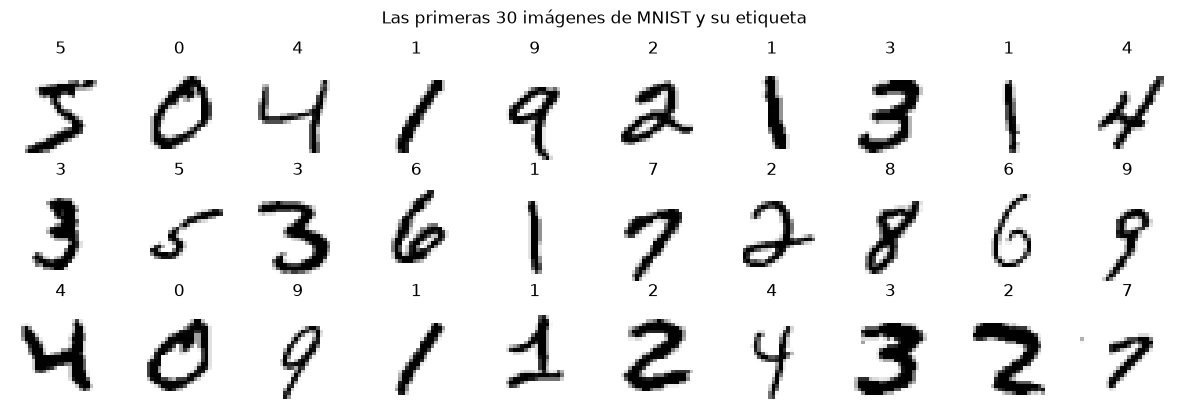

In [3]:
fig, ejes = plt.subplots(3, 10, figsize=(12, 4.2))
for k, ax in enumerate(ejes.flat):
    ax.imshow(X_train_255[k], cmap="gray_r")          # gray_r: tinta negra sobre fondo blanco, como en papel
    ax.set_title(int(y_train_todo[k]), fontsize=12)
    ax.axis("off")
plt.suptitle("Las primeras 30 imágenes de MNIST y su etiqueta")
plt.tight_layout(); plt.show()

### Una imagen es una tabla de números
Para el computador, la primera imagen (un 5) **no es un dibujo**: es una tabla de 28 filas y 28 columnas. Cada casilla es un píxel con un número de **0 a 255**: 0 es el fondo y 255 el trazo más intenso. (En el dibujo usamos tinta oscura sobre blanco para que se lea mejor; en los datos el fondo es 0.) Las casillas en blanco del dibujo valen 0: no les escribimos el número para que se pueda leer.

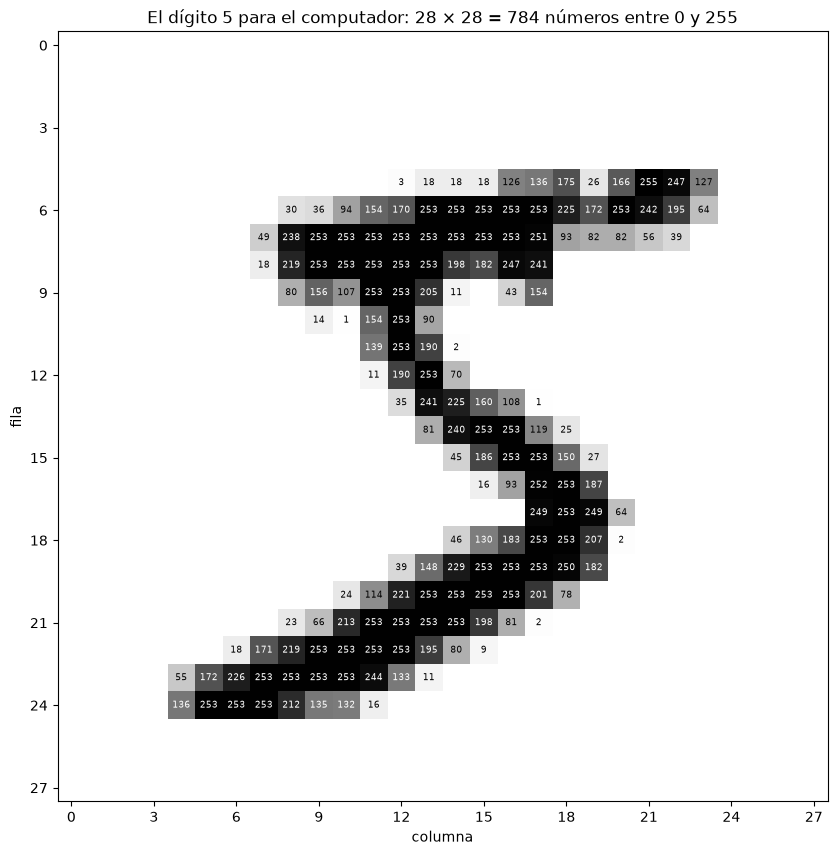

In [4]:
k = 0                                               # la primera imagen de entrenamiento
img = X_train_255[k].numpy()

fig, ax = plt.subplots(figsize=(10, 10))
ax.imshow(img, cmap="gray_r")
for i in range(28):                                  # fila
    for j in range(28):                              # columna
        if img[i, j] > 0:                            # los ceros no se escriben
            ax.text(j, i, img[i, j], ha="center", va="center", fontsize=6.5,
                    color="white" if img[i, j] > 128 else "black")
ax.set_xticks(range(0, 28, 3)); ax.set_yticks(range(0, 28, 3))
ax.set_xlabel("columna"); ax.set_ylabel("fila")
ax.set_title(f"El dígito {int(y_train_todo[k])} para el computador: 28 × 28 = 784 números entre 0 y 255")
plt.show()

### Preparar los datos: de 0–255 a 0–1, y la forma `(N, 1, 28, 28)`
1. **Escalar:** dividimos por 255 para que los píxeles queden entre 0 y 1. Es la misma idea de la semana 1 (las columnas de HIGGS ya venían estandarizadas): números pequeños y parecidos hacen el entrenamiento más estable.
2. **Agregar el canal:** una capa convolucional espera `(imágenes, canales, alto, ancho)`. Las imágenes en gris tienen **1 canal**; una foto a color tendría 3 (rojo, verde, azul).
3. **Separar validación:** apartamos 5 000 de las 60 000 imágenes de entrenamiento para mirar, época por época, cómo le va al modelo con imágenes que no usa para aprender. La prueba (10 000) no se toca hasta el final.

In [5]:
X_train_todo = (X_train_255.float() / 255).unsqueeze(1)     # (60000, 28, 28) → (60000, 1, 28, 28), valores entre 0 y 1
X_test = (X_test_255.float() / 255).unsqueeze(1)            # (10000, 1, 28, 28)

orden = torch.randperm(len(X_train_todo), generator=torch.Generator().manual_seed(SEMILLA))
val, tr = orden[:5_000], orden[5_000:]                      # 5 000 para validar, 55 000 para entrenar
X_tr, y_tr = X_train_todo[tr], y_train_todo[tr]
X_val, y_val = X_train_todo[val], y_train_todo[val]

print("Entrenar:", tuple(X_tr.shape), "| Validar:", tuple(X_val.shape), "| Prueba:", tuple(X_test.shape))
print(f"Píxeles ahora entre {X_tr.min():.0f} y {X_tr.max():.0f}")

Entrenar: (55000, 1, 28, 28) | Validar: (5000, 1, 28, 28) | Prueba: (10000, 1, 28, 28)
Píxeles ahora entre 0 y 1


## 2. La convolución, el tamaño de salida y el pooling

Una **capa convolucional** no mira la imagen entera de una vez. Usa un **filtro**: una tablita pequeña de números (en LeNet-5, de 5 × 5) que se pone encima de un pedazo de la imagen, multiplica casilla por casilla, **suma todo** y escribe ese único número en la salida. Luego el filtro se corre un píxel a la derecha y repite. Cuando llega al borde, baja una fila y vuelve a empezar. A eso se le llama **ventana deslizante**.

Al final, la salida es otra imagen (un **mapa de características**, *feature map*) que dice **en qué partes** de la imagen aparece lo que el filtro busca.

La convolución en movimiento, con los números reales, la vemos en la animación. Aquí quedan la fórmula del tamaño de salida y el ejemplo de max pooling, que usan los retos 2 y 3.

### ¿De qué tamaño sale la imagen? Padding y stride

Con una imagen de N × N y un filtro de F × F:

$$\text{salida} = \frac{N - F + 2P}{S} + 1$$

* **P, *padding* (relleno):** cuántos anillos de ceros se agregan alrededor de la imagen antes de pasar el filtro. Sirve para que la salida no se encoja y para que los bordes también queden en el centro de alguna ventana.
* **S, *stride* (paso):** de a cuántos píxeles salta la ventana. Con S = 2 se salta uno de cada dos: la salida queda de la mitad.

Si la división no da exacta, se redondea hacia abajo (la última ventana que no cabe completa se descarta). Comprobemos la fórmula contra PyTorch:

In [6]:
def tamano_salida(N, F, P=0, S=1):
    return (N - F + 2 * P) // S + 1                  # // divide y redondea hacia abajo


CASOS = [  # (N, F, P, S, qué pasa)
    (28, 3, 0, 1, "sin relleno: se encoge un poco"),
    (28, 3, 1, 1, "relleno de 1: queda del mismo tamaño ('same')"),
    (28, 5, 0, 1, "filtro de 5 × 5, como en LeNet-5"),
    (28, 5, 2, 1, "filtro de 5 × 5 con relleno de 2: mismo tamaño"),
    (28, 3, 1, 2, "paso de 2: la mitad"),
    (28, 3, 0, 2, "paso de 2 sin relleno: no da exacto, se redondea"),
]
filas = []
for N, F_, P, S, que in CASOS:
    capa = nn.Conv2d(1, 1, kernel_size=F_, padding=P, stride=S)
    con_pytorch = capa(torch.zeros(1, 1, N, N)).shape[-1]          # el tamaño que realmente sale
    filas.append({"N": N, "F": F_, "P": P, "S": S,
                  "fórmula": f"({N} − {F_} + 2·{P}) / {S} + 1 = {(N - F_ + 2 * P) / S + 1:g} → {tamano_salida(N, F_, P, S)}",
                  "PyTorch": f"{con_pytorch} × {con_pytorch}", "qué pasa": que})
display(pd.DataFrame(filas))

,N,F,P,S,fórmula,PyTorch,qué pasa
0,28,3,0,1,(28 − 3 + 2·0) / 1 + 1 = 26 → 26,26 × 26,sin relleno: se encoge un poco
1,28,3,1,1,(28 − 3 + 2·1) / 1 + 1 = 28 → 28,28 × 28,relleno de 1: queda del mismo tamaño ('same')
2,28,5,0,1,(28 − 5 + 2·0) / 1 + 1 = 24 → 24,24 × 24,"filtro de 5 × 5, como en LeNet-5"
3,28,5,2,1,(28 − 5 + 2·2) / 1 + 1 = 28 → 28,28 × 28,filtro de 5 × 5 con relleno de 2: mismo tamaño
4,28,3,1,2,(28 − 3 + 2·1) / 2 + 1 = 14.5 → 14,14 × 14,paso de 2: la mitad
5,28,3,0,2,(28 − 3 + 2·0) / 2 + 1 = 13.5 → 13,13 × 13,"paso de 2 sin relleno: no da exacto, se redondea"


### Max pooling: quedarse con el más fuerte de cada grupo
Después de una convolución, casi siempre viene un ***pooling***. El **max pooling de 2 × 2** parte el mapa en cuadritos de 2 × 2 que **no se pisan** (paso 2) y de cada uno guarda solo el **número más grande**. Así:
* el mapa queda de la **mitad** de alto y de la mitad de ancho (cuatro veces menos números);
* se conserva **si** el patrón apareció en esa zona, aunque se pierde el píxel exacto **dónde**. Esto ayuda a que la red tolere que el dígito esté un poquito corrido (lo veremos en el experimento 4).

El pooling **no tiene parámetros**: no aprende nada, solo resume.

In [7]:
mini = torch.tensor([[1., 3., 2., 0.],
                     [5., 6., 1., 2.],
                     [0., 2., 9., 4.],
                     [1., 0., 3., 7.]])
resumen = nn.MaxPool2d(kernel_size=2)(mini[None, None])[0, 0]      # (1, 1, 4, 4) → (1, 1, 2, 2)

print("Mapa de 4 × 4 (cuatro cuadritos de 2 × 2):")
display(pd.DataFrame(mini.numpy()).astype(int))
print("Después del max pooling 2 × 2:")
display(pd.DataFrame(resumen.numpy()).astype(int))
print("Cuadrito de arriba a la izquierda: máx(1, 3, 5, 6) = 6;  arriba a la derecha: máx(2, 0, 1, 2) = 2;  "
      "abajo a la izquierda: máx(0, 2, 1, 0) = 2;  abajo a la derecha: máx(9, 4, 3, 7) = 9")

Mapa de 4 × 4 (cuatro cuadritos de 2 × 2):


,0,1,2,3
0,1,3,2,0
1,5,6,1,2
2,0,2,9,4
3,1,0,3,7


Después del max pooling 2 × 2:


,0,1
0,6,2
1,2,9


Cuadrito de arriba a la izquierda: máx(1, 3, 5, 6) = 6;  arriba a la derecha: máx(2, 0, 1, 2) = 2;  abajo a la izquierda: máx(0, 2, 1, 0) = 2;  abajo a la derecha: máx(9, 4, 3, 7) = 9


## 3. Los competidores

| Modelo | Cómo ve la imagen | Capas |
|---|---|---|
| **Red densa (MLP)** | La **aplana**: la vuelve una fila de 784 números y cada neurona de la primera capa mira **los 784 a la vez**. | La red de la semana 1: 3 capas ocultas de 256 neuronas con ReLU. Solo cambian la entrada (784 en vez de 28) y la salida (10 en vez de 1). |
| **CNN (LeNet-5)** | La recorre con **filtros pequeños** (5 × 5) que buscan patrones locales en todas partes; solo al final aplana y decide. | conv 6 filtros 5×5 → max pool → conv 16 filtros 5×5 → max pool → aplanar → densa 120 → densa 84 → 10, con ReLU. |

**LeNet-5** es la versión moderna de la red de Yann LeCun (1998). La de LeCun, la original, usaba imágenes de 32 × 32, activación *tanh* y un pooling de promedio; hoy se usan ReLU y max pooling.

Pasemos **una** imagen por cada red y miremos la forma (`.shape`) que sale de cada capa:

In [8]:
def crear_densa():
    return nn.Sequential(
        nn.Flatten(),                                   # (N, 1, 28, 28) → (N, 784): la imagen se vuelve una fila
        nn.Linear(784, 256), nn.ReLU(),
        nn.Linear(256, 256), nn.ReLU(),
        nn.Linear(256, 256), nn.ReLU(),
        nn.Linear(256, 10))                             # 10 salidas: un puntaje por dígito


def crear_lenet():
    return nn.Sequential(
        nn.Conv2d(1, 6, kernel_size=5), nn.ReLU(),      # 6 filtros de 5 × 5 sobre 1 canal
        nn.MaxPool2d(2),
        nn.Conv2d(6, 16, kernel_size=5), nn.ReLU(),     # 16 filtros de 5 × 5 sobre los 6 mapas anteriores
        nn.MaxPool2d(2),
        nn.Flatten(),                                   # de mapas a una fila de números
        nn.Linear(16 * 4 * 4, 120), nn.ReLU(),
        nn.Linear(120, 84), nn.ReLU(),
        nn.Linear(84, 10))


def nombre_corto(capa):                                 # un nombre corto y legible para cada capa
    if isinstance(capa, nn.Conv2d):
        return f"Conv2d({capa.in_channels} → {capa.out_channels} filtros de {capa.kernel_size[0]}×{capa.kernel_size[1]})"
    if isinstance(capa, nn.Linear):
        return f"Linear({capa.in_features} → {capa.out_features})"
    if isinstance(capa, nn.MaxPool2d):
        return f"MaxPool2d({capa.kernel_size}×{capa.kernel_size})"
    return capa.__class__.__name__


def mostrar_formas(modelo, x):
    print(f"{'entrada':<34} → {tuple(x.shape)}")
    for capa in modelo:                                 # pasar la imagen capa por capa
        x = capa(x)
        print(f"{nombre_corto(capa):<34} → {tuple(x.shape)}")


una = X_tr[:1]                                          # una sola imagen: (1, 1, 28, 28)
print("RED DENSA"); mostrar_formas(crear_densa(), una)
print("\nCNN (LeNet-5)"); mostrar_formas(crear_lenet(), una)

RED DENSA
entrada                            → (1, 1, 28, 28)
Flatten                            → (1, 784)
Linear(784 → 256)                  → (1, 256)
ReLU                               → (1, 256)
Linear(256 → 256)                  → (1, 256)
ReLU                               → (1, 256)
Linear(256 → 256)                  → (1, 256)
ReLU                               → (1, 256)
Linear(256 → 10)                   → (1, 10)

CNN (LeNet-5)
entrada                            → (1, 1, 28, 28)
Conv2d(1 → 6 filtros de 5×5)       → (1, 6, 24, 24)
ReLU                               → (1, 6, 24, 24)
MaxPool2d(2×2)                     → (1, 6, 12, 12)
Conv2d(6 → 16 filtros de 5×5)      → (1, 16, 8, 8)
ReLU                               → (1, 16, 8, 8)
MaxPool2d(2×2)                     → (1, 16, 4, 4)
Flatten                            → (1, 256)
Linear(256 → 120)                  → (1, 120)
ReLU                               → (1, 120)
Linear(120 → 84)                   → (1, 84)
ReLU        

Sigamos la CNN con la fórmula del tamaño (P = 0, S = 1):
* **Conv 1:** (28 − 5)/1 + 1 = **24**. Salen 6 mapas de 24 × 24, uno por filtro.
* **Max pool:** 24 / 2 = **12**.
* **Conv 2:** (12 − 5)/1 + 1 = **8**. Salen 16 mapas de 8 × 8.
* **Max pool:** 8 / 2 = **4**. Quedan 16 mapas de 4 × 4 = **256** números, que se aplanan y pasan a la parte densa.

La imagen se **encoge** (28 → 24 → 12 → 8 → 4) mientras los canales **crecen** (1 → 6 → 16): cada vez menos "dónde" y más "qué".

### Contar parámetros a mano
* **Capa densa:** entradas × neuronas + sesgos (un sesgo por neurona).
* **Capa convolucional:** cada filtro tiene F × F × (canales que entran) pesos, más 1 sesgo. Total: **F × F × C_entrada × C_salida + C_salida**.
* Pooling, ReLU y Flatten: **0** parámetros.

| Red densa | Cuenta | Parámetros |
|---|---|---|
| Linear 784 → 256 | 784 × 256 + 256 | 200 960 |
| Linear 256 → 256 | 256 × 256 + 256 | 65 792 |
| Linear 256 → 256 | 256 × 256 + 256 | 65 792 |
| Linear 256 → 10 | 256 × 10 + 10 | 2 570 |
| **Total** | | **335 114** |

| CNN (LeNet-5) | Cuenta | Parámetros |
|---|---|---|
| Conv 6 filtros 5 × 5 (1 canal entra) | 5 × 5 × 1 × 6 + 6 | 156 |
| Conv 16 filtros 5 × 5 (6 canales entran) | 5 × 5 × 6 × 16 + 16 | 2 416 |
| Linear 256 → 120 | 256 × 120 + 120 | 30 840 |
| Linear 120 → 84 | 120 × 84 + 84 | 10 164 |
| Linear 84 → 10 | 84 × 10 + 10 | 850 |
| **Total** | | **44 426** |

Verifiquémoslo con código:

In [9]:
def contar_parametros(modelo):
    return sum(p.numel() for p in modelo.parameters())


def parametros_por_capa(modelo):
    filas = []
    for capa in modelo:
        if hasattr(capa, "weight"):                     # solo las capas que aprenden (Conv2d y Linear)
            filas.append({"capa": nombre_corto(capa), "forma de los pesos": tuple(capa.weight.shape),
                          "pesos": capa.weight.numel(), "sesgos": capa.bias.numel(),
                          "parámetros": contar_parametros(capa)})
    tabla = pd.DataFrame(filas)
    tabla.loc[len(tabla)] = ["TOTAL", "", tabla.pesos.sum(), tabla.sesgos.sum(), tabla["parámetros"].sum()]
    return tabla


print("RED DENSA"); display(parametros_por_capa(crear_densa()))
print("CNN (LeNet-5)"); display(parametros_por_capa(crear_lenet()))

RED DENSA


,capa,forma de los pesos,pesos,sesgos,parámetros
0,Linear(784 → 256),"(256, 784)",200704,256,200960
1,Linear(256 → 256),"(256, 256)",65536,256,65792
2,Linear(256 → 256),"(256, 256)",65536,256,65792
3,Linear(256 → 10),"(10, 256)",2560,10,2570
4,TOTAL,,334336,778,335114


CNN (LeNet-5)


,capa,forma de los pesos,pesos,sesgos,parámetros
0,Conv2d(1 → 6 filtros de 5×5),"(6, 1, 5, 5)",150,6,156
1,Conv2d(6 → 16 filtros de 5×5),"(16, 6, 5, 5)",2400,16,2416
2,Linear(256 → 120),"(120, 256)",30720,120,30840
3,Linear(120 → 84),"(84, 120)",10080,84,10164
4,Linear(84 → 10),"(10, 84)",840,10,850
5,TOTAL,,44190,236,44426


### La idea clave: el filtro se comparte
¿Por qué la primera capa de la CNN tiene solo **156** parámetros? Porque **el mismo filtro de 5 × 5 se usa en todas las posiciones** de la imagen. Un borde es un borde arriba, abajo o en la esquina: no hace falta aprender un detector distinto para cada lugar. A esto se le llama **pesos compartidos**.

¿Cuánto costaría producir esa misma salida (6 mapas de 24 × 24 = 3 456 números) con una capa **densa**, donde cada salida tiene sus propios pesos para los 784 píxeles?

In [10]:
salidas = 6 * 24 * 24                                   # lo que produce la primera convolución
densa_equivalente = 784 * salidas + salidas             # cada salida con sus 784 pesos + su sesgo
conv1 = 5 * 5 * 1 * 6 + 6
print(f"Primera convolución de LeNet-5: {conv1:,} parámetros")
print(f"Capa densa con la misma salida ({salidas:,} números): {densa_equivalente:,} parámetros")
print(f"→ {densa_equivalente / conv1:,.0f} veces más")

Primera convolución de LeNet-5: 156 parámetros
Capa densa con la misma salida (3,456 números): 2,712,960 parámetros
→ 17,391 veces más


### El ciclo de entrenamiento
Es el **mismo ciclo** de la semana 1. Solo cambian dos cosas:
* la pérdida es `CrossEntropyLoss` (entropía cruzada para **10 clases**, con el softmax adentro) en vez de la binaria;
* la predicción es la clase con el puntaje más alto (`argmax`), en vez de comparar con 0,5.

Usamos AdamW, lotes de 128 imágenes y **5 épocas**. Al final de cada época medimos pérdida y exactitud en entrenamiento y en validación, para dibujar las curvas.

In [11]:
@torch.no_grad()                                        # para predecir no hace falta guardar gradientes
def puntajes(modelo, X, lote=5_000):
    modelo.eval()
    return torch.cat([modelo(X[i:i + lote].to(DISPOSITIVO)).cpu() for i in range(0, len(X), lote)])


def evaluar(modelo, X, y):
    salida = puntajes(modelo, X)
    return F.cross_entropy(salida, y).item(), (salida.argmax(1) == y).float().mean().item()   # pérdida, exactitud


def entrenar(crear_modelo, X, y, X_val, y_val, epocas=EPOCAS, lote=128, semilla=SEMILLA, mostrar=True):
    torch.manual_seed(semilla)                          # misma semilla → mismos pesos iniciales en cada corrida
    modelo = crear_modelo().to(DISPOSITIVO)
    optimizador = torch.optim.AdamW(modelo.parameters(), lr=1e-3, weight_decay=1e-4)
    perdida_fn = nn.CrossEntropyLoss()
    Xd, yd = X.to(DISPOSITIVO), y.to(DISPOSITIVO)

    historia, t0 = [], time.time()
    for epoca in range(epocas):
        modelo.train()
        idx = torch.randperm(len(Xd), device=DISPOSITIVO)        # barajar en cada época
        for i in range(0, len(Xd), lote):
            b = idx[i:i + lote]
            optimizador.zero_grad()                              # 1. borrar los gradientes anteriores
            perdida = perdida_fn(modelo(Xd[b]), yd[b])           # 2. forward y pérdida
            perdida.backward()                                   # 3. backward: calcular gradientes
            optimizador.step()                                   # 4. mover los pesos
        p_tr, a_tr = evaluar(modelo, X, y)
        p_va, a_va = evaluar(modelo, X_val, y_val)
        historia.append({"época": epoca + 1, "pérdida entrenamiento": p_tr, "pérdida validación": p_va,
                         "exactitud entrenamiento": a_tr, "exactitud validación": a_va})
        if mostrar:
            print(f"  época {epoca + 1}: pérdida {p_tr:.4f} / {p_va:.4f}   exactitud {a_tr:.2%} / {a_va:.2%}   (entrenamiento / validación)")
    return modelo, pd.DataFrame(historia), time.time() - t0

## Experimento 1 · Entrenamiento y curvas

Entrenamos las dos redes con las mismas 55 000 imágenes, las mismas 5 épocas y el mismo optimizador. Al final medimos la exactitud en las 10 000 imágenes de **prueba**.

La red densa tiene **335 114** parámetros y la CNN **44 426** (7,5 veces menos).

In [12]:
COMPETIDORES = {"Red densa (MLP)": crear_densa, "CNN (LeNet-5)": crear_lenet}

resultados = {}
for nombre, crear in COMPETIDORES.items():
    print(nombre)
    modelo, historia, segundos = entrenar(crear, X_tr, y_tr, X_val, y_val)
    _, acc_test = evaluar(modelo, X_test, y_test)
    resultados[nombre] = {"modelo": modelo, "historia": historia, "segundos": segundos, "acc_test": acc_test}

densa, cnn = resultados["Red densa (MLP)"]["modelo"], resultados["CNN (LeNet-5)"]["modelo"]

Red densa (MLP)


  época 1: pérdida 0.1649 / 0.1940   exactitud 94.99% / 93.48%   (entrenamiento / validación)


  época 2: pérdida 0.0907 / 0.1268   exactitud 97.27% / 95.84%   (entrenamiento / validación)


  época 3: pérdida 0.0690 / 0.1110   exactitud 97.80% / 96.58%   (entrenamiento / validación)


  época 4: pérdida 0.0408 / 0.0855   exactitud 98.75% / 97.38%   (entrenamiento / validación)


  época 5: pérdida 0.0334 / 0.0855   exactitud 98.95% / 97.20%   (entrenamiento / validación)
CNN (LeNet-5)


  época 1: pérdida 0.1380 / 0.1514   exactitud 95.83% / 95.52%   (entrenamiento / validación)


  época 2: pérdida 0.0907 / 0.1093   exactitud 97.15% / 96.46%   (entrenamiento / validación)


  época 3: pérdida 0.0773 / 0.0894   exactitud 97.52% / 97.16%   (entrenamiento / validación)


  época 4: pérdida 0.0509 / 0.0659   exactitud 98.38% / 97.98%   (entrenamiento / validación)


  época 5: pérdida 0.0443 / 0.0573   exactitud 98.62% / 98.12%   (entrenamiento / validación)


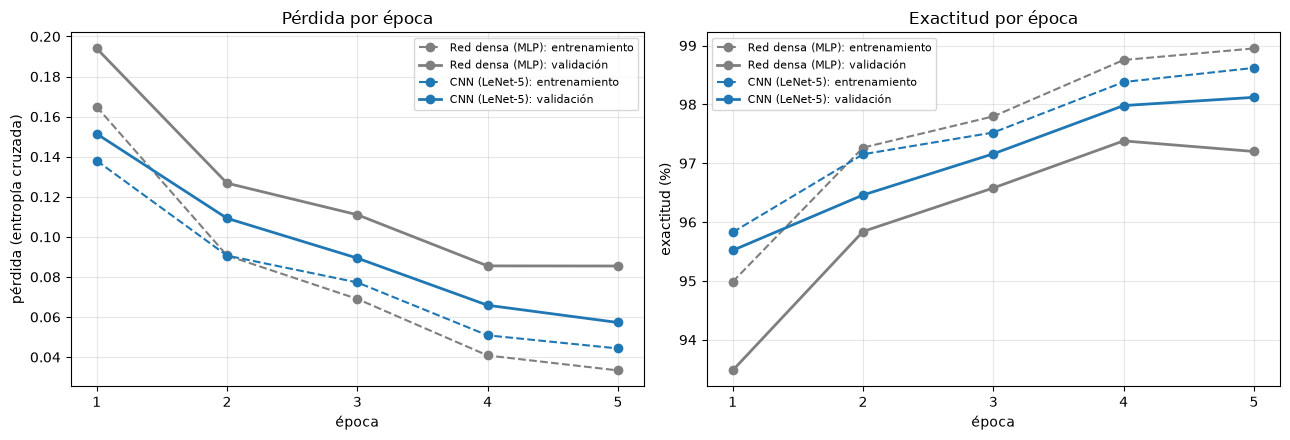

,parámetros,segundos de entrenamiento,exactitud validación (%),exactitud prueba (%),errores en prueba (de 10 000)
modelo,,,,,
Red densa (MLP),335114,14.6,97.20,97.80,220
CNN (LeNet-5),44426,29.9,98.12,98.37,163


In [13]:
fig, ejes = plt.subplots(1, 2, figsize=(13, 4.5))
for (nombre, r), color in zip(resultados.items(), ["tab:gray", "tab:blue"]):
    h = r["historia"]
    ejes[0].plot(h["época"], h["pérdida entrenamiento"], "o--", color=color, label=f"{nombre}: entrenamiento")
    ejes[0].plot(h["época"], h["pérdida validación"], "o-", color=color, lw=2, label=f"{nombre}: validación")
    ejes[1].plot(h["época"], 100 * h["exactitud entrenamiento"], "o--", color=color, label=f"{nombre}: entrenamiento")
    ejes[1].plot(h["época"], 100 * h["exactitud validación"], "o-", color=color, lw=2, label=f"{nombre}: validación")
ejes[0].set_ylabel("pérdida (entropía cruzada)"); ejes[1].set_ylabel("exactitud (%)")
for ax in ejes:
    ax.set_xlabel("época"); ax.grid(alpha=0.3); ax.legend(fontsize=8); ax.set_xticks(range(1, EPOCAS + 1))
ejes[0].set_title("Pérdida por época"); ejes[1].set_title("Exactitud por época")
plt.tight_layout(); plt.show()

resumen = pd.DataFrame([{"modelo": nombre,
                         "parámetros": contar_parametros(r["modelo"]),
                         "segundos de entrenamiento": round(r["segundos"], 1),
                         "exactitud validación (%)": round(100 * r["historia"]["exactitud validación"].iloc[-1], 2),
                         "exactitud prueba (%)": round(100 * r["acc_test"], 2),
                         "errores en prueba (de 10 000)": round(10_000 * (1 - r["acc_test"]))}
                        for nombre, r in resultados.items()]).set_index("modelo")
resumen

**Lectura:**
* **Gana la CNN, con 7,5 veces menos parámetros:** 98,53 % en prueba contra 97,70 % de la red densa. Dicho en errores: de 10 000 dígitos, la densa se equivoca en **230** y la CNN en **147**, un 36 % menos de errores.
* La densa tiene **335 114** parámetros y la CNN **44 426**. Tener más perillas no sirvió: lo que importa es que la **forma** de la red le sirva al problema. Es la misma lección de "ancha vs. profunda" de la semana 1, ahora con imágenes.
* Miren las curvas. En **entrenamiento** las dos terminan casi iguales (98,97 % la densa y 98,52 % la CNN en la época 5), pero en **validación** la CNN va arriba en las 5 épocas (en la última, 98,06 % contra 97,54 %). La densa tiene más distancia entre entrenamiento y validación: **memoriza más**. La CNN **generaliza mejor**.
* Menos parámetros no quiere decir menos tiempo: miren la columna de segundos: la CNN tarda más que la densa (los tiempos cambian en cada corrida y en cada computador, pero la CNN queda más lenta). Una multiplicación de matrices (la capa densa) es lo más rápido que hay en una GPU; las convoluciones y el pooling se organizan con más trabajo.

## Experimento 2 · ¿Qué aprendió la CNN?

Ahora miremos los **6 filtros de 5 × 5** que la CNN aprendió sola en su primera capa (rojo = peso positivo, azul = negativo), y lo que produce cada uno cuando le pasamos un dígito.

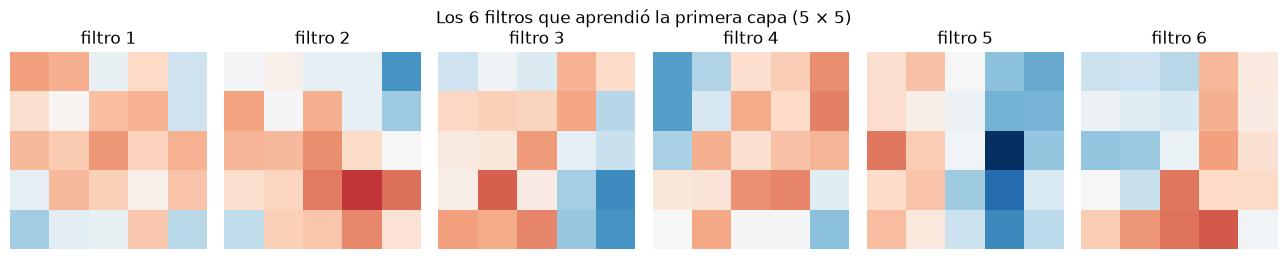

In [14]:
pesos = cnn[0].weight.detach().cpu()[:, 0]               # (6, 5, 5): los 6 filtros de la primera capa
tope = pesos.abs().max()
fig, ejes = plt.subplots(1, 6, figsize=(13, 2.6))
for k, ax in enumerate(ejes):
    ax.imshow(pesos[k], cmap="RdBu_r", vmin=-tope, vmax=tope)
    ax.set_title(f"filtro {k + 1}"); ax.axis("off")
plt.suptitle("Los 6 filtros que aprendió la primera capa (5 × 5)")
plt.tight_layout(); plt.show()

Y los mapas de características de un dígito de prueba: lo que sale de la primera convolución (6 mapas de 24 × 24) y de la segunda (16 mapas de 8 × 8), después de la ReLU. Blanco = el filtro se activó mucho; negro = nada.

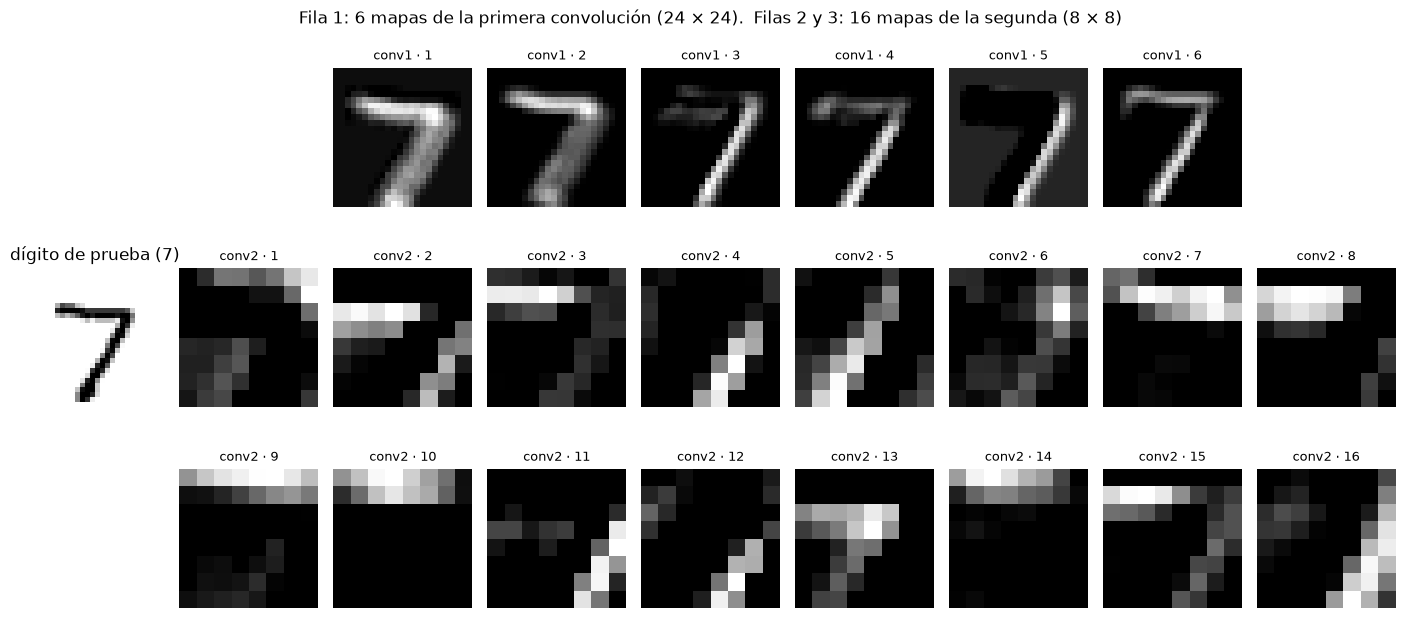

In [15]:
x = X_test[:1].to(DISPOSITIVO)                           # el primer dígito de prueba
with torch.no_grad():
    mapas1 = cnn[:2](x)[0].cpu()                         # conv1 + ReLU → (6, 24, 24)
    mapas2 = cnn[:5](x)[0].cpu()                         # conv1 + ReLU + pool + conv2 + ReLU → (16, 8, 8)

fig = plt.figure(figsize=(14, 6.5))
ax = fig.add_subplot(3, 9, (1, 19)); ax.imshow(X_test[0, 0], cmap="gray_r"); ax.axis("off")
ax.set_title(f"dígito de prueba ({int(y_test[0])})")
for k in range(6):
    ax = fig.add_subplot(3, 9, 3 + k); ax.imshow(mapas1[k], cmap="gray"); ax.axis("off")
    ax.set_title(f"conv1 · {k + 1}", fontsize=9)
for k in range(16):
    ax = fig.add_subplot(3, 9, 11 + k + (k >= 8)); ax.imshow(mapas2[k], cmap="gray"); ax.axis("off")
    ax.set_title(f"conv2 · {k + 1}", fontsize=9)
plt.suptitle("Fila 1: 6 mapas de la primera convolución (24 × 24).  Filas 2 y 3: 16 mapas de la segunda (8 × 8)")
plt.tight_layout(); plt.show()

**Lectura:**
* Los filtros aprendidos **no se parecen** a los filtros clásicos de bordes, hechos a mano (el de borde vertical es una columna de −1, una de 0 y una de +1: derecha menos izquierda): son más "borrosos" y mezclados. Nadie le dijo a la red que buscara bordes; los números salieron del descenso de gradiente, buscando bajar la pérdida.
* Aun así, varios tienen la misma idea de un detector de bordes: una zona azul (negativa) al lado de una roja (positiva). Por ejemplo, el filtro 4 es azul a la izquierda y rojo a la derecha, como un filtro de borde vertical. Nadie se lo enseñó.
* En la **primera capa** (24 × 24) los mapas todavía **parecen el 7**, pero cada uno resalta una parte: el 3 y el 4 se encienden sobre todo en el trazo diagonal y casi no ven la barra de arriba; el 5 hace lo contrario de los demás: se enciende un poco en el fondo y se apaga sobre el trazo.
* En la **segunda capa** (8 × 8) ya no se ve un 7: cada mapa dice **en qué zona** apareció una pieza. Varios se encienden solo arriba, donde está la barra (3, 7, 8, 9 y 10); otros a lo largo de la diagonal (4, 5, 12 y 16); otros en la esquina de arriba a la derecha, donde la barra se une con la diagonal (1 y 6).
* Así trabaja una CNN: la primera capa detecta **trazos** sencillos, la segunda **combina** trazos en **piezas** más grandes y la parte densa del final decide qué dígito es según qué piezas aparecieron y dónde. Es la idea de "componer" de la semana 1, ahora sobre la imagen.

## Experimento 3 · Los píxeles desordenados

Hagamos algo raro: elegimos **una sola** forma al azar de revolver los 784 píxeles y la aplicamos **igual a todas** las imágenes, de entrenamiento y de prueba. El píxel que estaba en la fila 3, columna 10, se va siempre a la misma posición nueva, en todas las imágenes.

No se pierde ninguna información: los 784 números siguen ahí y, si uno conoce la permutación, puede devolver la imagen a como estaba. Lo único que cambia es **quién queda al lado de quién**.

Así se ven:

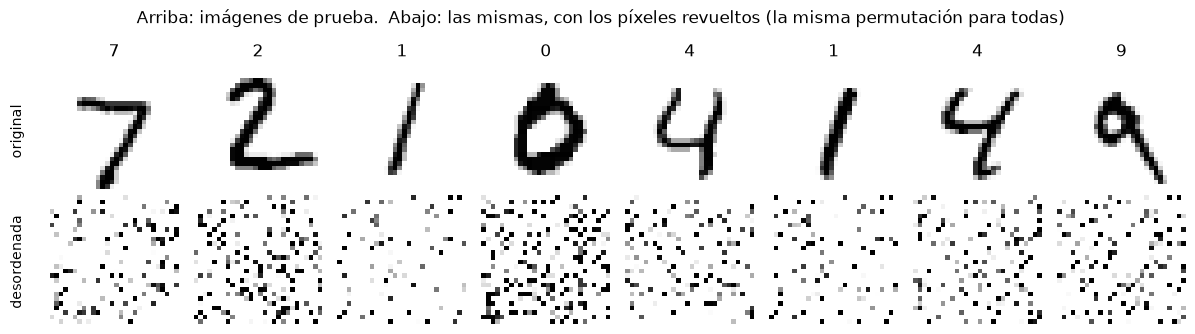

In [16]:
PERMUTACION = torch.randperm(784, generator=torch.Generator().manual_seed(SEMILLA))   # UNA sola, fija para siempre


def desordenar(X):
    return X.reshape(len(X), 784)[:, PERMUTACION].reshape(len(X), 1, 28, 28)


fig, ejes = plt.subplots(2, 8, figsize=(12, 3.4))
for k in range(8):
    ejes[0, k].imshow(X_test[k, 0], cmap="gray_r"); ejes[0, k].set_title(int(y_test[k]))
    ejes[1, k].imshow(desordenar(X_test[k:k + 1])[0, 0], cmap="gray_r")
for ax in ejes.flat:
    ax.axis("off")
ejes[0, 0].text(-6, 14, "original", rotation=90, va="center", ha="right")
ejes[1, 0].text(-6, 14, "desordenada", rotation=90, va="center", ha="right")
plt.suptitle("Arriba: imágenes de prueba.  Abajo: las mismas, con los píxeles revueltos (la misma permutación para todas)")
plt.tight_layout(); plt.show()

Para nosotros, la fila de abajo es ruido. Ahora **entrenamos de nuevo las dos redes desde cero**, con las imágenes desordenadas, y las probamos con las imágenes de prueba desordenadas de la misma forma.

Red densa (MLP) listo


CNN (LeNet-5) listo


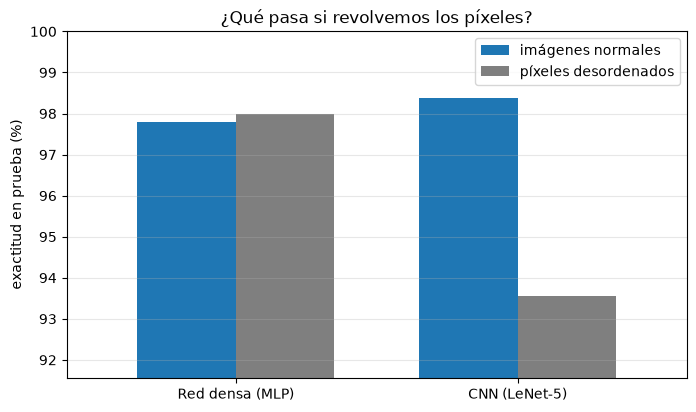

,imágenes normales,píxeles desordenados,cambio (puntos)
modelo,,,
Red densa (MLP),97.80,97.99,0.19
CNN (LeNet-5),98.37,93.56,-4.81


In [17]:
filas = []
for nombre, crear in COMPETIDORES.items():
    modelo, _, _ = entrenar(crear, desordenar(X_tr), y_tr, desordenar(X_val), y_val, mostrar=False)
    _, acc = evaluar(modelo, desordenar(X_test), y_test)
    filas.append({"modelo": nombre, "imágenes normales": 100 * resultados[nombre]["acc_test"],
                  "píxeles desordenados": 100 * acc})
    print(nombre, "listo")
tabla_permutada = pd.DataFrame(filas).set_index("modelo")
tabla_permutada["cambio (puntos)"] = tabla_permutada["píxeles desordenados"] - tabla_permutada["imágenes normales"]

ax = tabla_permutada[["imágenes normales", "píxeles desordenados"]].plot.bar(
    figsize=(8, 4.5), rot=0, color=["tab:blue", "tab:gray"], width=0.7)
ax.set_ylim(tabla_permutada.values[:, :2].min() - 2, 100)
ax.set_ylabel("exactitud en prueba (%)"); ax.set_xlabel(""); ax.grid(axis="y", alpha=0.3)
ax.set_title("¿Qué pasa si revolvemos los píxeles?"); plt.show()
tabla_permutada.round(2)

**Lectura (el resultado más importante de la clase):**
* **A la red densa no le pasó nada:** 97,70 % con las imágenes normales y 97,77 % con los píxeles revueltos. La diferencia (0,07 puntos) es ruido.
* **La CNN cayó 5,21 puntos:** de 98,53 % a 93,32 %. Pasó de ser la mejor a **perder** contra la densa.
* ¿Por qué a la densa no le importa? Su primera capa conecta **cada píxel con cada neurona** y no sabe qué píxel está al lado de cuál: para ella la imagen siempre fue una lista de 784 números. Revolver la lista igual para todas las imágenes es como cambiar el orden de las columnas de una hoja de Excel: la red aprende lo mismo, solo que con los pesos en otro orden.
* ¿Por qué a la CNN sí? Su filtro de 5 × 5 mira **25 píxeles vecinos** y da por hecho que lo que está cerca está relacionado: que un trazo sigue en el píxel de al lado. A esa suposición se le llama **localidad**. Al revolver, los vecinos ya no tienen nada que ver entre sí: no quedan bordes ni trazos que detectar. La CNN todavía llega a 93 % porque sus filtros y su parte densa pueden combinar píxeles sueltos, pero perdió su ventaja.
* **La ventaja de la CNN no es magia: es una suposición sobre los datos.** Si se cumple (en imágenes los vecinos importan), gana con menos parámetros. Si no se cumple, estorba.

## Experimento 4 · ¿Y si la imagen se mueve?

En MNIST todos los dígitos vienen **centrados**. ¿Qué pasa si a las imágenes de **prueba** las corremos unos píxeles a la derecha? Las redes **no se vuelven a entrenar**: son las mismas del experimento 1, que solo vieron dígitos centrados.

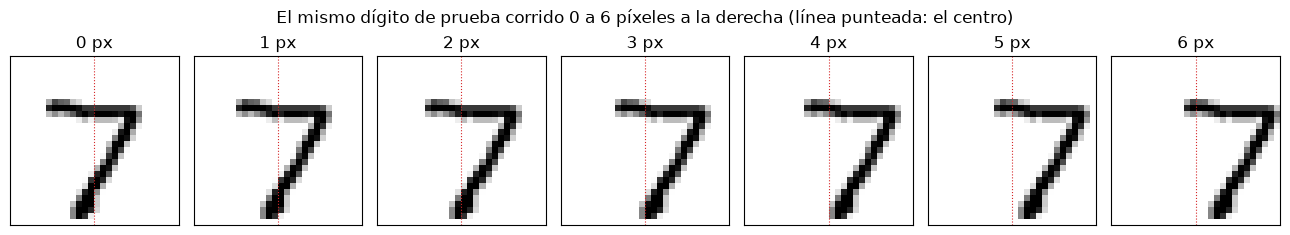

In [18]:
def mover(X, dx):
    # Corre las imágenes dx píxeles a la derecha y rellena con fondo (ceros) por la izquierda
    return F.pad(X, (dx, 0))[..., :28]                   # pegar dx columnas de ceros a la izquierda y cortar la derecha


CORRIMIENTOS = [0, 1, 2, 3, 4, 5, 6]
fig, ejes = plt.subplots(1, len(CORRIMIENTOS), figsize=(13, 2.4))
for ax, dx in zip(ejes, CORRIMIENTOS):
    ax.imshow(mover(X_test[:1], dx)[0, 0], cmap="gray_r")
    ax.axvline(13.5, color="tab:red", lw=0.8, ls=":")    # el centro de la imagen
    ax.set_title(f"{dx} px"); ax.set_xticks([]); ax.set_yticks([])
plt.suptitle("El mismo dígito de prueba corrido 0 a 6 píxeles a la derecha (línea punteada: el centro)")
plt.tight_layout(); plt.show()

Probamos con corrimientos de 0 a 6 píxeles, sin volver a entrenar (3 píxeles ya es un poco más de un décimo del ancho).

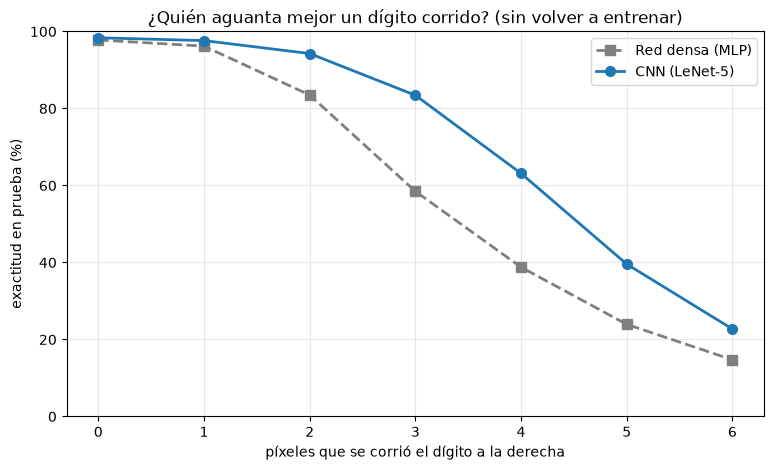

,Red densa (MLP),CNN (LeNet-5)
corrimiento (px),,
0,97.8,98.4
1,96.2,97.6
2,83.5,94.3
3,58.5,83.4
4,38.8,63.1
5,23.9,39.6
6,14.7,22.7


In [19]:
filas = []
for dx in CORRIMIENTOS:
    fila = {"corrimiento (px)": dx}
    for nombre, r in resultados.items():
        fila[nombre] = 100 * evaluar(r["modelo"], mover(X_test, dx), y_test)[1]
    filas.append(fila)
tabla_mover = pd.DataFrame(filas).set_index("corrimiento (px)")

plt.figure(figsize=(9, 5))
for (nombre, marca), color in zip([("Red densa (MLP)", "s--"), ("CNN (LeNet-5)", "o-")], ["tab:gray", "tab:blue"]):
    plt.plot(tabla_mover.index, tabla_mover[nombre], marca, color=color, lw=2, ms=7, label=nombre)
plt.xlabel("píxeles que se corrió el dígito a la derecha"); plt.ylabel("exactitud en prueba (%)")
plt.ylim(0, 100); plt.grid(alpha=0.3); plt.legend()
plt.title("¿Quién aguanta mejor un dígito corrido? (sin volver a entrenar)"); plt.show()
tabla_mover.round(1)

**Lectura:**
* Con **1 píxel** casi nada cambia (densa 95,4 %, CNN 97,9 %). Con **2 píxeles** la densa ya cae a **82,0 %** y la CNN se sostiene en **94,6 %**. Con **3 píxeles**: densa **59,6 %**, CNN **82,3 %**: casi 23 puntos de diferencia.
* La CNN **aguanta más** por dos razones:
  1. el **mismo filtro** se pasa por toda la imagen: si el trazo se corre, el mapa de características sale igual, solo que corrido;
  2. el **max pooling** se queda con el máximo de cada cuadrito de 2 × 2: si el trazo se movió un píxel dentro del cuadrito, el máximo no cambia.
* La densa, en cambio, aprendió **un peso para cada píxel**, algo como "si hay tinta en la fila 10, columna 14, súmele puntos al 7". Si el dígito se corre, la tinta cae en píxeles cuyos pesos dicen otra cosa.
* Pero la CNN **no es inmune**: con 4 píxeles baja a 59,3 % y con 6 a 21,8 % (adivinando al azar se saca 10 %). El pooling solo absorbe movimientos pequeños y la parte densa del final sí depende de la posición. En la práctica, esto se resuelve entrenando también con imágenes corridas, giradas o con zoom: se llama **aumento de datos** (*data augmentation*).

## Experimento 5 · Matriz de confusión y errores

La exactitud dice **cuántas** veces se equivoca la CNN, pero no **en qué**. La **matriz de confusión** lo muestra: cada fila es el dígito real y cada columna lo que dijo la red. La diagonal son los aciertos y todo lo que está por fuera son errores. Por ejemplo, la casilla (fila 4, columna 9) cuenta los 4 que la red leyó como 9.

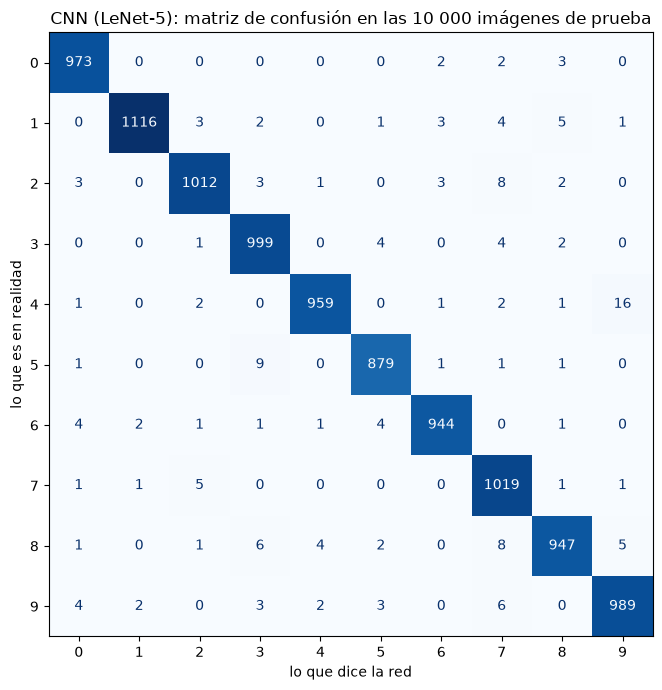

Exactitud de la CNN por dígito:


dígito,0,1,2,3,4,5,6,7,8,9
imágenes,980.00,1135.00,1032.00,1010.00,982.00,892.00,958.00,1028.00,974.00,1009.00
aciertos,973.00,1116.00,1012.00,999.00,959.00,879.00,944.00,1019.00,947.00,989.00
exactitud (%),99.29,98.33,98.06,98.91,97.66,98.54,98.54,99.12,97.23,98.02


Las confusiones más frecuentes:


,real,la red dice,errores
0,4,9,16
1,5,3,9
2,2,7,8
3,8,7,8
4,8,3,6
5,9,7,6
6,7,2,5
7,8,9,5


In [20]:
def matriz_confusion(modelo, X, y, nombres=None, titulo=""):
    pred = puntajes(modelo, X).argmax(1)
    mc = confusion_matrix(y, pred, labels=list(range(10)))
    etiquetas = nombres if nombres is not None else list(range(10))
    fig, ax = plt.subplots(figsize=(8, 7))
    ConfusionMatrixDisplay(mc, display_labels=etiquetas).plot(ax=ax, cmap="Blues", colorbar=False, values_format="d")
    ax.set_xlabel("lo que dice la red"); ax.set_ylabel("lo que es en realidad"); ax.set_title(titulo)
    if nombres is not None:
        plt.setp(ax.get_xticklabels(), rotation=45, ha="right")
    plt.tight_layout(); plt.show()
    return mc, pred


def confusiones_frecuentes(mc, nombres=None, n=8):
    # Las parejas (real → dice) con más errores, fuera de la diagonal
    nombres = nombres if nombres is not None else [str(i) for i in range(10)]
    filas = [{"real": nombres[i], "la red dice": nombres[j], "errores": int(mc[i, j])}
             for i in range(10) for j in range(10) if i != j]
    return pd.DataFrame(filas).sort_values("errores", ascending=False).head(n).reset_index(drop=True)


mc_cnn, pred_cnn = matriz_confusion(cnn, X_test, y_test, titulo="CNN (LeNet-5): matriz de confusión en las 10 000 imágenes de prueba")
por_clase = pd.DataFrame({"imágenes": mc_cnn.sum(1), "aciertos": mc_cnn.diagonal()}, index=range(10))
por_clase["exactitud (%)"] = (100 * por_clase["aciertos"] / por_clase["imágenes"]).round(2)
por_clase.index.name = "dígito"
print("Exactitud de la CNN por dígito:"); display(por_clase.T)
print("Las confusiones más frecuentes:"); display(confusiones_frecuentes(mc_cnn))

Y veamos **cuáles** imágenes falla: las 24 primeras que la CNN clasifica mal, con lo que es en realidad, lo que dijo y con qué probabilidad.

La CNN falla 163 de 10,000 imágenes de prueba


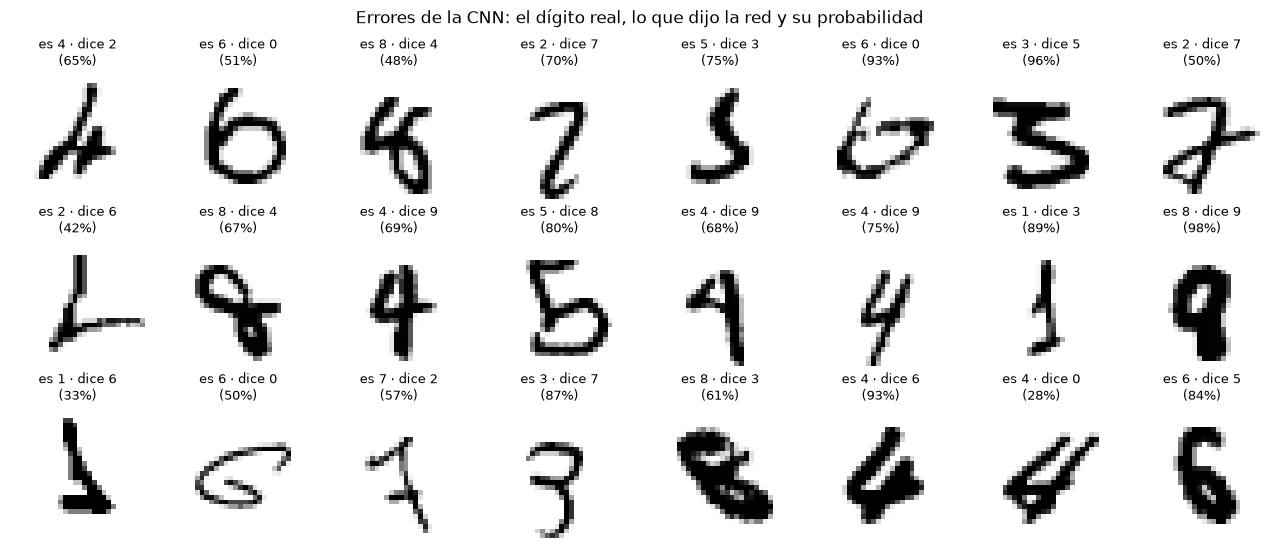

In [21]:
prob_cnn = puntajes(cnn, X_test).softmax(1)
errores = torch.nonzero(pred_cnn != y_test).flatten()
print(f"La CNN falla {len(errores)} de {len(y_test):,} imágenes de prueba")

fig, ejes = plt.subplots(3, 8, figsize=(13, 5.6))
for ax, k in zip(ejes.flat, errores[:24]):
    ax.imshow(X_test[k, 0], cmap="gray_r")
    ax.set_title(f"es {int(y_test[k])} · dice {int(pred_cnn[k])}\n({prob_cnn[k].max():.0%})", fontsize=9)
    ax.axis("off")
plt.suptitle("Errores de la CNN: el dígito real, lo que dijo la red y su probabilidad")
plt.tight_layout(); plt.show()

**Lectura:**
* **La CNN falla 163 de 10 000 imágenes (98,37 %), pero los errores no están repartidos parejo.** Con unas 1 000 imágenes por dígito, el ruido de la exactitud de cada dígito es de unos ± 0,45 puntos. Por eso la diferencia entre el mejor, el **0** (99,29 %), y el peor, el **8** (97,23 %, 27 errores), es real.
* **La casilla más grande fuera de la diagonal es 4 → 9: 16 errores**, el 10 % de todos los errores de la red. Al revés (9 → 4) solo hay **2**. La confusión va en un solo sentido: un 4 escrito con la parte de arriba **cerrada** tiene la misma forma que un 9 (en la figura de errores hay tres 4 así, leídos como 9 con 68–75 % de probabilidad). Un 9 casi nunca se escribe abierto, así que no se confunde con un 4.
* Las otras confusiones también son de formas que comparten trazos: **5 → 3** (9 errores; la mitad de abajo es igual y solo cambia la de arriba), **2 → 7** y **8 → 7** (8 cada una). El 8 es el que más reparte sus errores (a 7, 3, 9 y 4), porque tiene trazos de casi todos los demás dígitos.
* **Muchos errores son dígitos que hasta una persona dudaría en leer:** un 6 acostado, un 8 grueso e inclinado, un 1 con base, leído como 3 o como 6. Varios los dice con **poca confianza** (28 %, 33 %, 42 %, 50 %): la red "duda". Otros los dice muy segura (un 8 leído como 9 con 98 %).
* **Qué haría con esto:** en un lector de cheques no aceptaría la respuesta cuando la probabilidad es baja (por ejemplo, < 90 %) y mandaría esa imagen a revisión humana. Así se evitan muchos errores revisando pocas imágenes. Para el 4 ↔ 9, agregaría más ejemplos de 4 cerrados al entrenamiento.

## Cierre: ¿cuándo usar una CNN y cuándo una red densa?

| Modelo | ¿Cómo mira la imagen? | ¿Usa a los vecinos? | Parámetros | Prueba | Píxeles revueltos | Dígito corrido 3 px |
|---|---|---|---|---|---|---|
| **Red densa (MLP)** | Toda de una vez, como una lista de 784 números | No | 335 114 | 97,70 % | 97,77 % (igual) | 59,6 % |
| **CNN (LeNet-5)** | Por pedacitos de 5 × 5, con el mismo filtro en todas partes | Sí (localidad) | 44 426 | 98,53 % | 93,32 % (−5,2 puntos) | 82,3 % |

**Una analogía.** La red densa es como alguien que revisa un formulario **casilla por casilla**: se sabe de memoria qué debe haber en cada casilla, pero si el formulario llega corrido un centímetro, se pierde. La CNN es como alguien con una **lupa**: la pasa por toda la hoja buscando los mismos trazos (una línea, una curva, una esquina) estén donde estén, y después junta lo que vio para decidir. Por eso, si alguien revuelve los cuadritos de la hoja, la lupa ya no encuentra trazos, y al de las casillas le da igual.

Con la diferencia de que la lupa de la CNN no viene hecha: aprende sola qué buscar, usa varias lupas a la vez (6 en la primera capa, 16 en la segunda) y la segunda capa pasa su lupa sobre lo que encontró la primera, no sobre la imagen.

### ¿Dónde se usa esto?
* **LeNet leyó cheques de verdad.** A finales de los años 90, un sistema de lectura de cheques basado en las redes convolucionales del equipo de Yann LeCun (AT&T Bell Labs, vendido por NCR) llegó a leer más del 10 % de los cheques de Estados Unidos.
* **Hoy:** la misma idea lee facturas, formularios y documentos de identidad (*OCR*, reconocimiento óptico de caracteres), las placas de los carros en peajes y parqueaderos, y las direcciones de los sobres en el correo. Las redes son mucho más grandes, pero el primer paso sigue siendo pasar filtros por la imagen.
* **Lo que sigue:** redes convolucionales mucho más profundas (VGG, ResNet, EfficientNet, MobileNet) que ya vienen entrenadas con millones de fotos, y cómo aprovecharlas cuando uno tiene pocos datos (*transfer learning*, ejercicio 2).

## Retos para entregar

Son **4 retos distintos**: cada uno es un trabajo propio, con su propio código. Ninguno es "repetir el cuaderno entero".

**Cómo entregar:** al final de este cuaderno, hagan una sección por reto: `### Reto 1`, `### Reto 2`, … Debajo de cada una van el código que escribieron, su salida (tablas o gráficas) y una celda de texto con las respuestas a las preguntas del reto.

**Antes de empezar:** corran el cuaderno completo una vez, de arriba abajo. Los retos usan cosas que ya quedaron creadas arriba: `crear_lenet`, `entrenar`, `evaluar`, `mostrar_formas`, `mover`, `X_tr`, `X_test`, `resultados`…

### Cómo se responden las preguntas

No basta con **describir** lo que salió. Cada respuesta tiene que **explicar o suponer por qué** salió así, apoyada en los números. Una buena respuesta tiene cuatro partes:
1. **El dato**, con su número.
2. **¿Es real o es ruido?** Con 10.000 imágenes de prueba, 1 imagen = 0,01 puntos y el ruido de una exactitud cercana a 98 % es de unos ± 0,15 puntos. Una diferencia más pequeña que eso no es un resultado.
3. **La causa:** qué en los datos, en el modelo o en el entrenamiento explica el resultado.
4. **Qué harían con eso:** qué decisión tomarían o qué probarían después.

Un ejemplo, con el experimento 1:
- **Descripción (no responde la pregunta):** «La CNN sacó 98,53 % y la densa 97,70 %.»
- **Análisis (sí la responde):** «La CNN comete 147 errores contra 230 de la densa: 36 % menos. La diferencia, 0,83 puntos, es varias veces el ruido (± 0,15), así que es real. En entrenamiento las dos aciertan casi igual; la diferencia está en que la densa memoriza: su brecha entre entrenamiento y validación crece hasta 1,4 puntos, porque tiene un peso para cada píxel. La CNN usa el mismo filtro en todas partes y aprende trazos que sirven en imágenes nuevas. Si quisiera mejorar la densa, la regularizaría (dropout, aumento de datos) en vez de entrenarla más.»

Las respuestas que solo copian números de las tablas no responden la pregunta.

---

### Reto 1 · Su propio dígito

**Qué tienen que hacer:**
1. En un papel **blanco**, con un **marcador oscuro**, escriban los **10 dígitos (0 a 9)**, cada uno grande y separado de los demás.
2. Tómenle una foto a **cada dígito por separado**: una foto por número, bien de frente, con buena luz.
3. Suban las 10 fotos a la carpeta del cuaderno. En Colab: `from google.colab import files; files.upload()` u otro que prefieran.
4. Para **cada** foto, corran estas tres líneas. Están en la celda de ayuda de abajo:
   ```python
   x = preparar_como_mnist("foto_3.jpg")      # el nombre de SU archivo
   plt.imshow(x[0, 0], cmap="gray"); plt.show()   # revisen que se vea como un dígito de MNIST: trazo blanco sobre fondo negro, centrado
   predecir_digito(x)                          # qué dice cada red y con qué probabilidad
   ```
5. Armen una tabla con las 10 fotos:

   | dígito que escribieron | la red densa dice | probabilidad | la CNN dice | probabilidad |
   |---|---|---|---|---|

**Qué responden:**
- ¿Cuántos de los 10 acierta la red densa? ¿Y la CNN? Con solo 10 fotos, ¿se puede decir que una es mejor que la otra? ¿Por qué?
- ¿Cuáles fallaron? Para cada falla, expliquen **por qué** pasó, comparando su imagen preparada con las de MNIST (centrado, grosor del trazo, forma del dígito). ¿Fallan las dos redes en los mismos dígitos? ¿Por qué sí o por qué no?

*Pista:* piensen en el experimento 4, donde el dígito se corre unos píxeles. Miren también cómo escriben ustedes el 1, el 4 y el 7 comparado con los de MNIST; por ejemplo, ¿ponen la rayita del 7?

---

### Reto 2 · Padding, stride y dilatación

Van a cambiar **solo la primera capa** de LeNet-5 (`nn.Conv2d(1, 6, kernel_size=5)`) de **3 formas**, una a la vez. El resto de la red queda igual.

| caso | la primera capa queda así |
|---|---|
| A · padding | `nn.Conv2d(1, 6, kernel_size=5, padding=2)` |
| B · stride | `nn.Conv2d(1, 6, kernel_size=5, stride=2)` |
| C · dilatación | `nn.Conv2d(1, 6, kernel_size=5, dilation=2)`: un filtro "con huecos" que mira una zona de 9 × 9 con los mismos 25 pesos. Es la convolución *atrous* de las diapositivas. |

**Para cada caso (A, B y C), hagan estos 5 pasos en orden:**
1. **Calculen a mano** el tamaño de salida de **cada capa**, de la entrada (28 × 28) hasta `Flatten`. Usen la fórmula de la sección 2: salida = (N − F + 2P) / S + 1, redondeando hacia abajo. Con dilatación, el filtro "mide" d · (F − 1) + 1 en vez de F. Recuerden que cada `MaxPool2d(2)` divide el lado por 2.
2. **Escriban la red nueva** copiando `crear_lenet` y cambiando la primera capa. Ejemplo para el caso A:
   ```python
   def crear_lenet_A():
       return nn.Sequential(
           nn.Conv2d(1, 6, kernel_size=5, padding=2), nn.ReLU(),   # ← lo único que cambia aquí
           nn.MaxPool2d(2),
           nn.Conv2d(6, 16, kernel_size=5), nn.ReLU(),
           nn.MaxPool2d(2),
           nn.Flatten(),
           nn.Linear(16 * ? * ?, 120), nn.ReLU(),                  # ← ? = el lado del último mapa, de su cálculo del paso 1
           nn.Linear(120, 84), nn.ReLU(),
           nn.Linear(84, 10))
   ```
   El número de entrada de la primera `nn.Linear` es **16 × lado × lado**, con el lado del último mapa que les dio en el paso 1. Si no encaja, PyTorch da un error de formas (`mat1 and mat2 shapes cannot be multiplied`).
3. **Comprueben su cálculo** con `mostrar_formas(crear_lenet_A(), X_tr[:1])`. Las formas que imprime deben coincidir con las del paso 1.
4. **Cuenten los parámetros** con `contar_parametros(crear_lenet_A())` y `parametros_por_capa(crear_lenet_A())`.
5. **Entrenen y evalúen:**
   ```python
   modelo_A, historia_A, segundos_A = entrenar(crear_lenet_A, X_tr, y_tr, X_val, y_val)
   _, acc_A = evaluar(modelo_A, X_test, y_test)
   ```

**Qué entregan:** una tabla con 4 filas: LeNet-5 original, A, B y C.

| red | lado de salida de conv1 | entrada de la 1.ª Linear | parámetros de conv1 | parámetros totales | exactitud en prueba (%) |
|---|---|---|---|---|---|

**Qué responden:**
- ¿Cambia la exactitud en algún caso? ¿Cuál fue el mejor y cuál el peor? ¿Las diferencias son más grandes que el ruido (unos ± 0,15 puntos)? Expliquen **por qué**, con lo que cada cambio le hace al tamaño de los mapas y a la zona de la imagen que ve cada filtro.
- ¿Cambia el número de parámetros **de la convolución** (conv1)? ¿Y el **total** de la red? ¿Por qué uno sí y el otro no?

---

### Reto 3 · Average pooling vs. max pooling

Van a cambiar **los dos** `nn.MaxPool2d(2)` de LeNet-5 por `nn.AvgPool2d(2)`, que se queda con el **promedio** de cada cuadrito de 2 × 2 en vez del máximo.

**Qué tienen que hacer:**
1. **A mano primero:** tomen el mapa de 4 × 4 de la sección 2 (el de la celda de max pooling, `mini`) y calculen el **promedio** de cada uno de sus 4 cuadritos de 2 × 2. Compárenlo con el resultado del max pooling (6, 2, 2, 9).
2. Compruébenlo con código: `nn.AvgPool2d(2)(mini[None, None])[0, 0]`.
3. Escriban `crear_lenet_avg()`, una copia de `crear_lenet` con los dos `MaxPool2d(2)` cambiados por `AvgPool2d(2)`. El resto queda igual.
4. **Entrénenla y evalúenla** como en el reto 2:
   ```python
   modelo_avg, historia_avg, segundos_avg = entrenar(crear_lenet_avg, X_tr, y_tr, X_val, y_val)
   _, acc_avg = evaluar(modelo_avg, X_test, y_test)
   ```
5. **Repitan el experimento 4** (el dígito corrido) con esta red, sin volver a entrenarla:
   ```python
   for dx in CORRIMIENTOS:
       print(dx, 100 * evaluar(modelo_avg, mover(X_test, dx), y_test)[1])
   ```

**Qué entregan:** el cálculo a mano del paso 1 y una tabla con la exactitud de las dos redes (max y avg) para cada corrimiento, de 0 a 6 píxeles.

**Qué responden:**
- ¿Cambia la exactitud sin corrimiento? ¿Es más que el ruido (unos ± 0,15 puntos)?
- Con corrimiento, ¿cuál de las dos aguanta mejor? ¿Por qué creen que pasa, pensando en lo que guarda cada una (el más fuerte vs. el promedio)?

---

### Reto 4 · Fashion-MNIST: lo mismo, pero con ropa

Fashion-MNIST tiene la misma forma que MNIST: imágenes de 28 × 28 en gris, 10 clases, 60 000 de entrenamiento y 10 000 de prueba. Pero en vez de dígitos son **prendas**: 0 camiseta, 1 pantalón, 2 suéter, 3 vestido, 4 abrigo, 5 sandalia, 6 camisa, 7 tenis, 8 bolso, 9 botín.

**Qué tienen que hacer:**
1. **Hagan una copia de este cuaderno** (Archivo → Guardar una copia) para no borrar sus resultados de MNIST.
2. En la copia, en la celda **"1. Los datos: MNIST"**, cambien **3 cosas**:
   - `datasets.MNIST(` → `datasets.FashionMNIST(` en las **dos** líneas, la de `entrenamiento` y la de `prueba`;
   - en la línea de `YA_ESTA`, `"MNIST"` → `"FashionMNIST"`.
3. Corran la copia desde arriba **hasta el final del experimento 3**. No hace falta ir más allá.
4. Corran también la celda de la matriz de confusión del **experimento 5**, para ver qué prendas se confunden.

**Qué entregan:** una tabla con la exactitud en prueba de las dos redes en los dos datasets, y la matriz de confusión de la CNN con Fashion-MNIST.

| | red densa | CNN | ventaja de la CNN (puntos) |
|---|---|---|---|
| MNIST (dígitos) | | | |
| Fashion-MNIST (ropa) | | | |

**Qué responden:**
- ¿La ventaja de la CNN sobre la densa es **mayor o menor** que con dígitos? Expliquen **por qué**, pensando en qué distingue una prenda de otra (trazos y texturas locales, o la forma completa).
- En el experimento 3 (píxeles desordenados), ¿pasa lo mismo que con dígitos? ¿Por qué?
- Según la matriz de confusión, ¿qué prendas se confunden más entre sí? ¿Por qué esas, y en qué sentido van los errores?

### Ayuda para el reto 1: preparar una foto como MNIST
Una foto de celular **no se parece** a MNIST: es grande, a color, con tinta oscura sobre papel claro, con sombras y el dígito en cualquier parte. La función repite los pasos con los que se armó MNIST: gris, invertir, borrar el fondo, recortar el dígito, llevarlo a 20 × 20 sin deformarlo y centrarlo en un lienzo de 28 × 28.

Para probarla sin foto, abajo **simulamos** una: tomamos un dígito de prueba, lo agrandamos, lo ponemos oscuro sobre un "papel" gris claro con ruido y sin centrar.

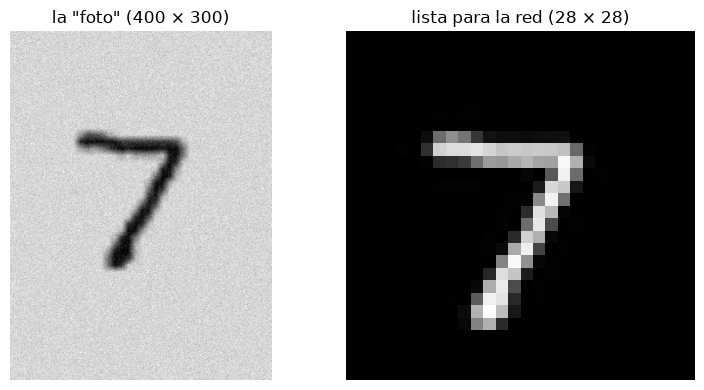

Red densa (MLP): dice 7 con 99% de probabilidad
CNN (LeNet-5): dice 7 con 100% de probabilidad


In [22]:
from PIL import Image, ImageOps


def preparar_como_mnist(foto):
    # Convierte la foto de UN dígito (tinta oscura sobre papel claro) en un tensor (1, 1, 28, 28) como los de MNIST
    img = Image.open(foto) if isinstance(foto, str) else foto
    a = np.asarray(ImageOps.grayscale(img), dtype=np.float32) / 255     # 1. gris, entre 0 y 1
    if a.mean() > 0.5:                                                  # 2. MNIST es trazo claro sobre fondo negro:
        a = 1 - a                                                       #    si el papel es claro, invertir
    a = np.where(a > 0.35, a, 0)                                        # 3. borrar el fondo (sombras, textura del papel)
    filas, columnas = np.nonzero(a)
    a = a[filas.min():filas.max() + 1, columnas.min():columnas.max() + 1]   # 4. recortar justo alrededor del dígito
    lado = max(a.shape)
    cuadro = np.zeros((lado, lado), dtype=np.float32)                   # 5. hacerlo cuadrado sin deformarlo
    f0, c0 = (lado - a.shape[0]) // 2, (lado - a.shape[1]) // 2
    cuadro[f0:f0 + a.shape[0], c0:c0 + a.shape[1]] = a
    chico = Image.fromarray((cuadro * 255).astype(np.uint8)).resize((20, 20), Image.LANCZOS)   # 6. a 20 × 20
    lienzo = np.zeros((28, 28), dtype=np.float32)                       # 7. pegarlo en un lienzo de 28 × 28
    lienzo[4:24, 4:24] = np.asarray(chico, dtype=np.float32) / 255
    f, c = np.indices(lienzo.shape)                                     # 8. centrarlo por su "centro de masa", como MNIST
    df = round(13.5 - (f * lienzo).sum() / lienzo.sum())
    dc = round(13.5 - (c * lienzo).sum() / lienzo.sum())
    lienzo = np.roll(lienzo, (df, dc), axis=(0, 1))
    return torch.tensor(lienzo)[None, None]


def predecir_digito(x):
    for nombre, r in resultados.items():
        p = puntajes(r["modelo"], x).softmax(1)[0]
        print(f"{nombre}: dice {p.argmax().item()} con {p.max():.0%} de probabilidad")


# ---- Simulación de una foto: un 7 de prueba, grande, oscuro sobre papel gris claro y sin centrar ----
rng = np.random.default_rng(0)
digito = Image.fromarray(X_test_255[0].numpy()).resize((220, 220), Image.BILINEAR)
papel = rng.normal(215, 12, size=(400, 300)).clip(0, 255)               # papel claro con textura
papel[60:280, 30:250] -= np.asarray(digito, dtype=np.float32) * 0.8     # tinta oscura
foto = Image.fromarray(papel.clip(0, 255).astype(np.uint8))

x = preparar_como_mnist(foto)
fig, ejes = plt.subplots(1, 2, figsize=(8, 4))
ejes[0].imshow(foto, cmap="gray", vmin=0, vmax=255); ejes[0].set_title("la \"foto\" (400 × 300)")
ejes[1].imshow(x[0, 0], cmap="gray"); ejes[1].set_title("lista para la red (28 × 28)")
for ax in ejes:
    ax.axis("off")
plt.tight_layout(); plt.show()
predecir_digito(x)

# ---- Con su foto ----
# En Colab, para subirla: from google.colab import files; files.upload()
# x = preparar_como_mnist("mi_digito.jpg")
# plt.imshow(x[0, 0], cmap="gray"); plt.show()       # revisen que se vea como los de MNIST
# predecir_digito(x)

### Reto 1 · Su propio dígito

Las fotos van en la misma carpeta del cuaderno, con los nombres `foto_0.jpg`, `foto_1.jpg`, …, `foto_9.jpg` (también sirve `.png` o `.jpeg`). La celda busca las 10, prepara cada una con `preparar_como_mnist`, la muestra y arma la tabla con lo que dice cada red.

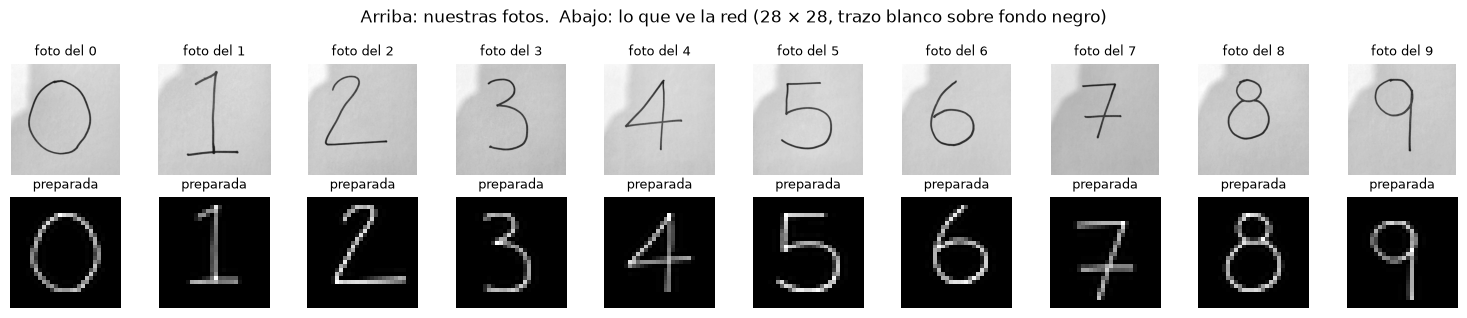

,archivo,la red densa dice,probabilidad densa,la CNN dice,probabilidad CNN
dígito que escribimos,,,,,
0,foto_0.jpeg,5,18%,0,38%
1,foto_1.jpeg,1,49%,1,25%
2,foto_2.jpeg,1,35%,2,21%
3,foto_3.jpeg,3,39%,3,33%
4,foto_4.jpeg,4,56%,4,46%
5,foto_5.jpeg,5,62%,5,60%
6,foto_6.jpeg,6,36%,6,37%
7,foto_7.jpeg,7,62%,7,53%
8,foto_8.jpeg,5,29%,5,25%


Aciertos de la red densa: 7 de 10
Aciertos de la CNN:       9 de 10


In [23]:
import glob


def predecir_tabla(x):
    # Igual que predecir_digito, pero devuelve los resultados para armar la tabla
    salida = {}
    for nombre, r in resultados.items():
        p = puntajes(r["modelo"], x).softmax(1)[0]
        salida[nombre] = (p.argmax().item(), p.max().item())
    return salida


fotos = {}
for d in range(10):
    encontradas = sorted(glob.glob(f"foto_{d}.*"))
    if encontradas:
        fotos[d] = encontradas[0]

if not fotos:
    print("Todavía no hay fotos en la carpeta (foto_0.jpg ... foto_9.jpg). Súbanlas y vuelvan a correr esta celda.")
else:
    filas, preparadas = [], {}
    for d, archivo in fotos.items():
        x = preparar_como_mnist(archivo)
        preparadas[d] = x
        pred = predecir_tabla(x)
        (d_densa, p_densa), (d_cnn, p_cnn) = pred["Red densa (MLP)"], pred["CNN (LeNet-5)"]
        filas.append({"dígito que escribimos": d, "archivo": archivo,
                      "la red densa dice": d_densa, "probabilidad densa": f"{p_densa:.0%}",
                      "la CNN dice": d_cnn, "probabilidad CNN": f"{p_cnn:.0%}"})

    fig, ejes = plt.subplots(2, len(preparadas), figsize=(1.4 * len(preparadas) + 1, 3.2), squeeze=False)
    for col, (d, x) in enumerate(preparadas.items()):
        ejes[0, col].imshow(ImageOps.exif_transpose(Image.open(fotos[d])).convert("L"), cmap="gray")
        ejes[0, col].set_title(f"foto del {d}", fontsize=9)
        ejes[1, col].imshow(x[0, 0], cmap="gray"); ejes[1, col].set_title("preparada", fontsize=9)
    for ax in ejes.flat:
        ax.axis("off")
    plt.suptitle("Arriba: nuestras fotos.  Abajo: lo que ve la red (28 × 28, trazo blanco sobre fondo negro)")
    plt.tight_layout(); plt.show()

    tabla_fotos = pd.DataFrame(filas).set_index("dígito que escribimos")
    display(tabla_fotos)
    print("Aciertos de la red densa:", (tabla_fotos["la red densa dice"] == tabla_fotos.index).sum(), "de", len(tabla_fotos))
    print("Aciertos de la CNN:      ", (tabla_fotos["la CNN dice"] == tabla_fotos.index).sum(), "de", len(tabla_fotos))

**Respuestas del reto 1**

| dígito que escribimos | la red densa dice | probabilidad | la CNN dice | probabilidad |
|---|---|---|---|---|
| 0 | **5** ✗ | 18 % | 0 | 38 % |
| 1 | 1 | 49 % | 1 | 25 % |
| 2 | **1** ✗ | 35 % | 2 | 21 % |
| 3 | 3 | 39 % | 3 | 33 % |
| 4 | 4 | 56 % | 4 | 46 % |
| 5 | 5 | 62 % | 5 | 60 % |
| 6 | 6 | 36 % | 6 | 37 % |
| 7 | 7 | 62 % | 7 | 53 % |
| 8 | **5** ✗ | 29 % | **5** ✗ | 25 % |
| 9 | 9 | 42 % | 9 | 31 % |
| **aciertos** | **7 de 10** | | **9 de 10** | |

*Nota:* la primera vez tomamos las fotos en un cuaderno **rayado**, con poca luz (papel gris, brillo ≈ 0,57) y con sombras. La función de preparación invertía la imagen, pero el papel quedaba en ≈ 0,43, por encima de su umbral de 0,35: la hoja entera se tomaba como trazo y las dos redes fallaron **los 10** dígitos. Repetimos las fotos en hoja blanca y con buena luz. Esa primera prueba ya muestra que **la red solo funciona si la entrada se parece a lo que vio al entrenar**.

**¿Cuántos acierta cada red? Con solo 10 fotos, ¿se puede decir que una es mejor?**
* La CNN acierta **9 de 10** y la densa **7 de 10**. Va en la misma dirección que el experimento 1, pero **con 10 fotos no se puede concluir que una sea mejor**. Cada foto vale 10 puntos, y la diferencia son solo 2 fotos. Con 10 intentos, una red que en el fondo acierta el 80 % puede sacar 7 o 9 solo por suerte: el margen de error de una exactitud medida con 10 imágenes es de unos ± 25–30 puntos. Para comparar redes hacen falta miles de imágenes, como las 10 000 de prueba, donde 1 imagen = 0,01 puntos.
* **Lo que sí dicen las fotos con claridad son las probabilidades.** En la prueba de MNIST las dos redes suelen decir su respuesta con 99–100 % (como en la simulación de la celda de ayuda). Con nuestras fotos, incluso cuando aciertan, lo dicen con **21 % a 62 %**. Las redes notan que estas imágenes son "raras". **Por qué:** al prepararlas, nuestro trazo quedó **delgado y tenue**: su píxel más brillante vale entre 0,27 y 0,45, cuando en MNIST el trazo llega a 1,0 y tiene 2 o 3 píxeles de grueso. Las dos redes usan ReLU, así que si la imagen tiene la mitad de "tinta", los puntajes de salida también salen más bajos y más parecidos entre sí. El softmax de puntajes parecidos da probabilidades repartidas, sin un ganador claro.

**¿Cuáles fallaron y por qué? ¿Fallan las dos redes en los mismos dígitos?**
* **El 8 lo fallan las dos, y las dos dicen 5** (29 % y 25 %: casi adivinando). Nuestro 8 tiene el **lazo de arriba pequeño** y el de abajo grande, con un trazo delgado. Lo que más se ve es el lazo de abajo, que es justo la curva de abajo de un 5. El lazo de arriba, pequeño y tenue, aporta poca señal y se parece a la parte de arriba del 5. Además, el 8 es el dígito que la CNN más falla también en MNIST (97,23 % en el experimento 5): tiene trazos de casi todos los demás dígitos. Que fallen **las dos** indica que el problema está en la imagen (trazo tenue, forma poco típica), no en una de las redes.
* **El 0 y el 2 solo los falla la densa:** el 0 lo dice 5 con 18 % (casi al azar, que sería 10 %) y el 2 lo dice 1 con 35 %. La CNN acierta los dos. **Por qué:** la densa aprendió **un peso para cada píxel**, es decir, en qué casillas suele haber tinta para cada dígito. Un 0 de MNIST es un óvalo **grueso**: con un trazo de 1 píxel, nuestro óvalo enciende pocas de esas casillas y en lugares un poco distintos. Para la densa es como el dígito corrido del experimento 4. Nuestro 2 tiene una diagonal casi **recta** y una base larga y plana, distinta del 2 curvo típico de MNIST: la densa ve sobre todo un trazo largo inclinado y dice 1. La CNN, en cambio, busca **trazos** con el mismo filtro en todas partes: un borde curvo o una esquina siguen siendo eso aunque estén un píxel corridos o sean más delgados. Por eso aguanta mejor las diferencias de grosor y de posición.
* El **1 con base** y el **7 con rayita**, que no son la forma típica de MNIST, los aciertan las dos, aunque con poca confianza en el 1 (49 % y 25 %).

**Qué haríamos con esto:** escribiríamos con un marcador más grueso y negro, o la función de preparación podría **estirar el contraste** (llevar el trazo más fuerte a 1,0) y **engrosar** el trazo antes de pasarlo a la red. Así las imágenes se parecerían más a MNIST. Para un sistema real (leer formularios), en vez de "arreglar" cada foto, entrenaríamos con **aumento de datos**: trazos más delgados, más gruesos, corridos y con distinto contraste.

### Reto 2 · Padding, stride y dilatación

**Paso 1 · Cálculo a mano.** Fórmula: salida = ⌊(N − F + 2P) / S⌋ + 1. Con dilatación d, el filtro "mide" F' = d · (F − 1) + 1 = 2 · 4 + 1 = **9**. Cada `MaxPool2d(2)` divide el lado por 2 (redondeando hacia abajo). Conv 2 es siempre igual: F = 5, P = 0, S = 1.

| capa | Original | A · padding = 2 | B · stride = 2 | C · dilatación = 2 |
|---|---|---|---|---|
| entrada | 28 | 28 | 28 | 28 |
| conv1 | (28 − 5)/1 + 1 = **24** | (28 − 5 + 4)/1 + 1 = **28** | ⌊(28 − 5)/2⌋ + 1 = ⌊11,5⌋ + 1 = **12** | (28 − 9)/1 + 1 = **20** |
| max pool | 12 | 14 | 6 | 10 |
| conv2 | (12 − 5) + 1 = 8 | (14 − 5) + 1 = 10 | (6 − 5) + 1 = 2 | (10 − 5) + 1 = 6 |
| max pool | 4 | 5 | 1 | 3 |
| Flatten (16 × lado²) | 16 × 4² = **256** | 16 × 5² = **400** | 16 × 1² = **16** | 16 × 3² = **144** |

**Parámetros a mano.** conv1 = 5 × 5 × 1 × 6 + 6 = **156** en los cuatro casos (padding, stride y dilatación no cambian el tamaño del filtro). Lo que cambia es la primera `Linear`: entradas × 120 + 120.

| red | 1.ª Linear | total |
|---|---|---|
| Original | 256 × 120 + 120 = 30 840 | 156 + 2 416 + 30 840 + 10 164 + 850 = **44 426** |
| A | 400 × 120 + 120 = 48 120 | **61 706** |
| B | 16 × 120 + 120 = 2 040 | **15 626** |
| C | 144 × 120 + 120 = 17 400 | **30 986** |

**Paso 2 · Las redes nuevas:**

In [24]:
def crear_lenet_A():                                    # A · padding = 2
    return nn.Sequential(
        nn.Conv2d(1, 6, kernel_size=5, padding=2), nn.ReLU(),   # 28 → 28
        nn.MaxPool2d(2),                                        # 28 → 14
        nn.Conv2d(6, 16, kernel_size=5), nn.ReLU(),             # 14 → 10
        nn.MaxPool2d(2),                                        # 10 → 5
        nn.Flatten(),
        nn.Linear(16 * 5 * 5, 120), nn.ReLU(),
        nn.Linear(120, 84), nn.ReLU(),
        nn.Linear(84, 10))


def crear_lenet_B():                                    # B · stride = 2
    return nn.Sequential(
        nn.Conv2d(1, 6, kernel_size=5, stride=2), nn.ReLU(),    # 28 → 12
        nn.MaxPool2d(2),                                        # 12 → 6
        nn.Conv2d(6, 16, kernel_size=5), nn.ReLU(),             # 6 → 2
        nn.MaxPool2d(2),                                        # 2 → 1
        nn.Flatten(),
        nn.Linear(16 * 1 * 1, 120), nn.ReLU(),
        nn.Linear(120, 84), nn.ReLU(),
        nn.Linear(84, 10))


def crear_lenet_C():                                    # C · dilatación = 2 (filtro de 5 × 5 que cubre 9 × 9)
    return nn.Sequential(
        nn.Conv2d(1, 6, kernel_size=5, dilation=2), nn.ReLU(),  # 28 → 20
        nn.MaxPool2d(2),                                        # 20 → 10
        nn.Conv2d(6, 16, kernel_size=5), nn.ReLU(),             # 10 → 6
        nn.MaxPool2d(2),                                        # 6 → 3
        nn.Flatten(),
        nn.Linear(16 * 3 * 3, 120), nn.ReLU(),
        nn.Linear(120, 84), nn.ReLU(),
        nn.Linear(84, 10))


VARIANTES = {"LeNet-5 original": crear_lenet, "A · padding = 2": crear_lenet_A,
             "B · stride = 2": crear_lenet_B, "C · dilatación = 2": crear_lenet_C}

**Paso 3 · Comprobar el cálculo con PyTorch.** Las formas deben coincidir con la tabla de arriba:

In [25]:
for nombre, crear in list(VARIANTES.items())[1:]:
    print(nombre); mostrar_formas(crear(), X_tr[:1]); print()

A · padding = 2
entrada                            → (1, 1, 28, 28)
Conv2d(1 → 6 filtros de 5×5)       → (1, 6, 28, 28)
ReLU                               → (1, 6, 28, 28)
MaxPool2d(2×2)                     → (1, 6, 14, 14)
Conv2d(6 → 16 filtros de 5×5)      → (1, 16, 10, 10)
ReLU                               → (1, 16, 10, 10)
MaxPool2d(2×2)                     → (1, 16, 5, 5)
Flatten                            → (1, 400)
Linear(400 → 120)                  → (1, 120)
ReLU                               → (1, 120)
Linear(120 → 84)                   → (1, 84)
ReLU                               → (1, 84)
Linear(84 → 10)                    → (1, 10)

B · stride = 2
entrada                            → (1, 1, 28, 28)
Conv2d(1 → 6 filtros de 5×5)       → (1, 6, 12, 12)
ReLU                               → (1, 6, 12, 12)
MaxPool2d(2×2)                     → (1, 6, 6, 6)
Conv2d(6 → 16 filtros de 5×5)      → (1, 16, 2, 2)
ReLU                               → (1, 16, 2, 2)
MaxPool2d(2×2)        

**Paso 4 · Contar los parámetros:**

In [26]:
for nombre, crear in list(VARIANTES.items())[1:]:
    print(f"{nombre}: {contar_parametros(crear()):,} parámetros")
    display(parametros_por_capa(crear()))

A · padding = 2: 61,706 parámetros


,capa,forma de los pesos,pesos,sesgos,parámetros
0,Conv2d(1 → 6 filtros de 5×5),"(6, 1, 5, 5)",150,6,156
1,Conv2d(6 → 16 filtros de 5×5),"(16, 6, 5, 5)",2400,16,2416
2,Linear(400 → 120),"(120, 400)",48000,120,48120
3,Linear(120 → 84),"(84, 120)",10080,84,10164
4,Linear(84 → 10),"(10, 84)",840,10,850
5,TOTAL,,61470,236,61706


B · stride = 2: 15,626 parámetros


,capa,forma de los pesos,pesos,sesgos,parámetros
0,Conv2d(1 → 6 filtros de 5×5),"(6, 1, 5, 5)",150,6,156
1,Conv2d(6 → 16 filtros de 5×5),"(16, 6, 5, 5)",2400,16,2416
2,Linear(16 → 120),"(120, 16)",1920,120,2040
3,Linear(120 → 84),"(84, 120)",10080,84,10164
4,Linear(84 → 10),"(10, 84)",840,10,850
5,TOTAL,,15390,236,15626


C · dilatación = 2: 30,986 parámetros


,capa,forma de los pesos,pesos,sesgos,parámetros
0,Conv2d(1 → 6 filtros de 5×5),"(6, 1, 5, 5)",150,6,156
1,Conv2d(6 → 16 filtros de 5×5),"(16, 6, 5, 5)",2400,16,2416
2,Linear(144 → 120),"(120, 144)",17280,120,17400
3,Linear(120 → 84),"(84, 120)",10080,84,10164
4,Linear(84 → 10),"(10, 84)",840,10,850
5,TOTAL,,30750,236,30986


**Paso 5 · Entrenar y evaluar** (mismas 5 épocas, mismo optimizador y misma semilla que la LeNet-5 original, que ya está entrenada en `resultados`):

In [27]:
resultados_reto2 = {"LeNet-5 original": resultados["CNN (LeNet-5)"]}
for nombre, crear in list(VARIANTES.items())[1:]:
    print(nombre)
    modelo, historia, segundos = entrenar(crear, X_tr, y_tr, X_val, y_val)
    _, acc = evaluar(modelo, X_test, y_test)
    resultados_reto2[nombre] = {"modelo": modelo, "historia": historia, "segundos": segundos, "acc_test": acc}

filas = []
for nombre, r in resultados_reto2.items():
    m = r["modelo"].cpu()
    lado_conv1 = m[:1](X_tr[:1]).shape[-1]
    filas.append({"red": nombre,
                  "lado de salida de conv1": lado_conv1,
                  "entrada de la 1.ª Linear": m[7].in_features,
                  "parámetros de conv1": contar_parametros(m[0]),
                  "parámetros totales": contar_parametros(m),
                  "exactitud validación (%)": round(100 * r["historia"]["exactitud validación"].iloc[-1], 2),
                  "exactitud prueba (%)": round(100 * r["acc_test"], 2),
                  "errores en prueba": round(10_000 * (1 - r["acc_test"])),
                  "segundos": round(r["segundos"], 1)})
    r["modelo"].to(DISPOSITIVO)
tabla_reto2 = pd.DataFrame(filas).set_index("red")
tabla_reto2["vs. original (puntos)"] = (tabla_reto2["exactitud prueba (%)"] - tabla_reto2.loc["LeNet-5 original", "exactitud prueba (%)"]).round(2)
tabla_reto2

A · padding = 2


  época 1: pérdida 0.1246 / 0.1330   exactitud 96.24% / 95.74%   (entrenamiento / validación)


  época 2: pérdida 0.0754 / 0.0798   exactitud 97.57% / 97.52%   (entrenamiento / validación)


  época 3: pérdida 0.0580 / 0.0685   exactitud 98.16% / 98.00%   (entrenamiento / validación)


  época 4: pérdida 0.0416 / 0.0510   exactitud 98.65% / 98.56%   (entrenamiento / validación)


  época 5: pérdida 0.0365 / 0.0553   exactitud 98.79% / 98.50%   (entrenamiento / validación)


... (8 outputs left out)

  época 3: pérdida 0.1061 / 0.1174   exactitud 96.72% / 96.02%   (entrenamiento / validación)


  época 4: pérdida 0.0875 / 0.0964   exactitud 97.31% / 96.94%   (entrenamiento / validación)


  época 5: pérdida 0.0706 / 0.0830   exactitud 97.81% / 97.22%   (entrenamiento / validación)


,lado de salida de conv1,entrada de la 1.ª Linear,parámetros de conv1,parámetros totales,exactitud validación (%),exactitud prueba (%),errores en prueba,segundos,vs. original (puntos)
red,,,,,,,,,
LeNet-5 original,24,256,156,44426,98.12,98.37,163,29.9,0.00
A · padding = 2,28,400,156,61706,98.50,98.58,142,36.4,0.21
B · stride = 2,12,16,156,15626,96.02,97.00,300,13.3,-1.37
C · dilatación = 2,20,144,156,30986,97.22,97.82,218,23.2,-0.55


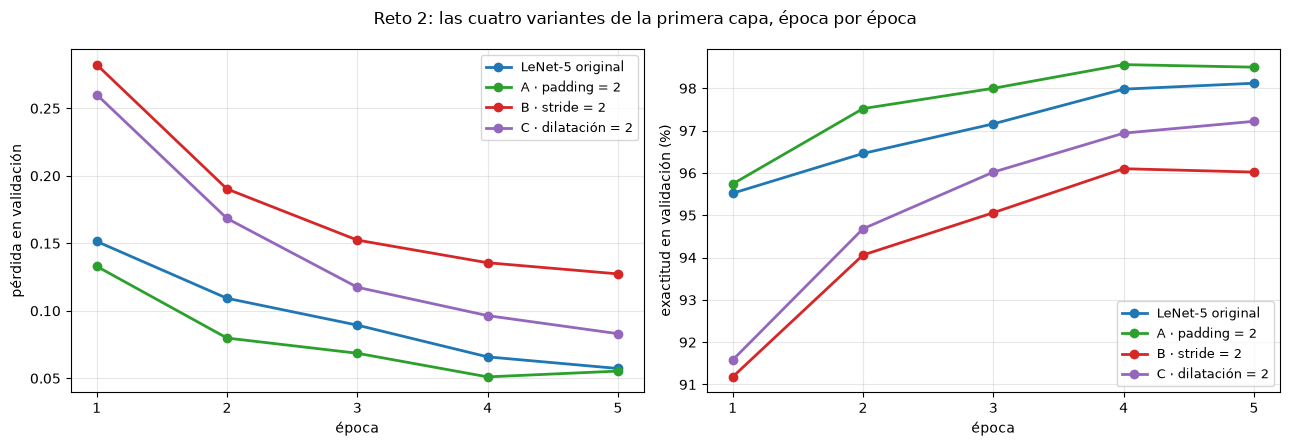

In [28]:
fig, ejes = plt.subplots(1, 2, figsize=(13, 4.5))
for (nombre, r), color in zip(resultados_reto2.items(), ["tab:blue", "tab:green", "tab:red", "tab:purple"]):
    h = r["historia"]
    ejes[0].plot(h["época"], h["pérdida validación"], "o-", color=color, lw=2, label=nombre)
    ejes[1].plot(h["época"], 100 * h["exactitud validación"], "o-", color=color, lw=2, label=nombre)
ejes[0].set_ylabel("pérdida en validación"); ejes[1].set_ylabel("exactitud en validación (%)")
for ax in ejes:
    ax.set_xlabel("época"); ax.grid(alpha=0.3); ax.legend(fontsize=9); ax.set_xticks(range(1, EPOCAS + 1))
plt.suptitle("Reto 2: las cuatro variantes de la primera capa, época por época")
plt.tight_layout(); plt.show()

**Respuestas del reto 2**

| red | lado de salida de conv1 | entrada de la 1.ª Linear | parámetros de conv1 | parámetros totales | exactitud en prueba (%) |
|---|---|---|---|---|---|
| LeNet-5 original | 24 | 256 | 156 | 44 426 | 98,37 |
| A · padding = 2 | 28 | 400 | 156 | 61 706 | **98,58** |
| B · stride = 2 | 12 | 16 | 156 | 15 626 | **97,00** |
| C · dilatación = 2 | 20 | 144 | 156 | 30 986 | 97,82 |

Las formas que imprimió `mostrar_formas` coinciden con el cálculo a mano en los tres casos.

**¿Cambia la exactitud? ¿Cuál fue el mejor y cuál el peor?**
* **El mejor fue A (padding): 98,58 %, 142 errores contra 163 de la original (+0,21 puntos).** La diferencia está apenas por encima del ruido (± 0,15), así que sola sería débil. Pero en validación va en el mismo sentido (98,50 % contra 98,12 %, +0,38), así que creemos que es una mejora real, aunque pequeña. **Por qué:** con relleno, la salida de conv1 no se encoge (28 en vez de 24). Los píxeles del borde también quedan en el centro de alguna ventana, y el último mapa queda de 5 × 5 en vez de 4 × 4: la parte densa recibe 400 números en vez de 256, con más detalle de **dónde** está cada trazo. El costo: 39 % más parámetros (61 706) y algo más de tiempo de entrenamiento (36,4 s contra 29,9 s en esta corrida; los tiempos cambian en cada ejecución).
* **El peor fue B (stride = 2): 97,00 %, 300 errores, casi el doble que la original (−1,37 puntos, nueve veces el ruido).** **Por qué:** el filtro salta de a 2 píxeles y pasa por encima de la mitad de las posiciones. En MNIST los trazos tienen 2 o 3 píxeles de grueso, así que se pierde detalle fino desde la primera capa. Además, al encadenar stride y dos poolings, la imagen se reduce hasta **1 × 1**: a la parte densa solo le llegan 16 números (uno por filtro), que dicen **qué** apareció pero no **dónde**. Distinguir un 6 de un 9 requiere saber dónde está el círculo. La curva lo confirma: B empieza más abajo (91,18 % en validación en la época 1) y nunca alcanza a la original.
* **C (dilatación) quedó en la mitad: 97,82 %, 218 errores (−0,55 puntos, real).** **Por qué:** el filtro dilatado mira una zona de 9 × 9, pero con huecos: sus 25 pesos caen cada 2 píxeles. Un trazo de 1 o 2 píxeles de ancho puede caer justo en un hueco, así que la primera capa ve los trazos "a saltos". Ver más contexto no ayuda en la primera capa, cuando lo que hay que detectar son bordes finos. La dilatación sirve más en capas profundas y en imágenes grandes, donde se necesita contexto amplio sin perder resolución. Su validación seguía subiendo en la época 5 (96,94 → 97,22), así que con más épocas probablemente se acercaría un poco más.

**¿Cambian los parámetros de conv1? ¿Y el total? ¿Por qué uno sí y el otro no?**
* **Los de conv1, no: son 156 en los cuatro casos** (5 × 5 × 1 × 6 + 6). Los parámetros de una convolución dependen solo del tamaño del filtro y de cuántos canales entran y salen. El padding cambia la imagen (le agrega ceros), el stride cambia cómo se mueve el filtro y la dilatación cambia la separación entre sus pesos. Ninguno cambia cuántos pesos tiene el filtro: es la idea de **pesos compartidos**.
* **El total sí cambia (de 15 626 a 61 706)** porque cambia el **tamaño de los mapas**, y la primera `Linear` tiene un peso por cada número que le llega: 16 × lado² × 120. Ese lado depende de padding, stride y dilatación. Toda la diferencia de parámetros está en esa capa densa, no en la convolución.

**Qué haríamos con esto:** dejaríamos el padding (A), que gana un poco a cambio de más tiempo y parámetros. No usaríamos stride en la primera capa con imágenes tan pequeñas como 28 × 28: el pooling ya reduce la imagen, y hacer las dos cosas la deja sin información de posición. Si hiciera falta reducir cómputo con imágenes grandes, el stride sí tendría sentido.

### Reto 3 · Average pooling vs. max pooling

**Paso 1 · A mano.** El mapa `mini` de la sección 2, partido en sus cuatro cuadritos de 2 × 2:

| cuadrito | valores | máximo (max pooling) | promedio (avg pooling) |
|---|---|---|---|
| arriba a la izquierda | 1, 3, 5, 6 | **6** | (1 + 3 + 5 + 6) / 4 = 15 / 4 = **3,75** |
| arriba a la derecha | 2, 0, 1, 2 | **2** | (2 + 0 + 1 + 2) / 4 = 5 / 4 = **1,25** |
| abajo a la izquierda | 0, 2, 1, 0 | **2** | (0 + 2 + 1 + 0) / 4 = 3 / 4 = **0,75** |
| abajo a la derecha | 9, 4, 3, 7 | **9** | (9 + 4 + 3 + 7) / 4 = 23 / 4 = **5,75** |

El promedio siempre es menor o igual que el máximo: el max pooling se queda con el pico ("aquí apareció el patrón con fuerza 9"), y el avg pooling lo mezcla con los vecinos, que suelen ser más débiles.

**Paso 2 · Comprobarlo con código:**

In [29]:
promedio = nn.AvgPool2d(2)(mini[None, None])[0, 0]
maximo = nn.MaxPool2d(2)(mini[None, None])[0, 0]
print("Avg pooling 2 × 2:"); display(pd.DataFrame(promedio.numpy()))
print("Max pooling 2 × 2 (para comparar):"); display(pd.DataFrame(maximo.numpy()).astype(int))

Avg pooling 2 × 2:


,0,1
0,3.75,1.25
1,0.75,5.75


Max pooling 2 × 2 (para comparar):


,0,1
0,6,2
1,2,9


**Pasos 3 y 4 · La red con average pooling, entrenada y evaluada:**

In [30]:
def crear_lenet_avg():
    return nn.Sequential(
        nn.Conv2d(1, 6, kernel_size=5), nn.ReLU(),
        nn.AvgPool2d(2),                                # ← promedio en vez de máximo
        nn.Conv2d(6, 16, kernel_size=5), nn.ReLU(),
        nn.AvgPool2d(2),                                # ← promedio en vez de máximo
        nn.Flatten(),
        nn.Linear(16 * 4 * 4, 120), nn.ReLU(),
        nn.Linear(120, 84), nn.ReLU(),
        nn.Linear(84, 10))


print(f"Parámetros: {contar_parametros(crear_lenet_avg()):,} (los mismos que la original: el pooling no aprende nada)")
modelo_avg, historia_avg, segundos_avg = entrenar(crear_lenet_avg, X_tr, y_tr, X_val, y_val)
_, acc_avg = evaluar(modelo_avg, X_test, y_test)
acc_max = resultados["CNN (LeNet-5)"]["acc_test"]
print(f"\nExactitud en prueba · max pooling: {acc_max:.2%} ({round(10_000 * (1 - acc_max))} errores)   "
      f"avg pooling: {acc_avg:.2%} ({round(10_000 * (1 - acc_avg))} errores)   diferencia: {100 * (acc_avg - acc_max):+.2f} puntos")

Parámetros: 44,426 (los mismos que la original: el pooling no aprende nada)


  época 1: pérdida 0.1911 / 0.2140   exactitud 94.40% / 93.34%   (entrenamiento / validación)


  época 2: pérdida 0.1047 / 0.1229   exactitud 96.86% / 96.16%   (entrenamiento / validación)


  época 3: pérdida 0.0831 / 0.0945   exactitud 97.48% / 97.18%   (entrenamiento / validación)


  época 4: pérdida 0.0762 / 0.0890   exactitud 97.62% / 97.28%   (entrenamiento / validación)


  época 5: pérdida 0.0570 / 0.0640   exactitud 98.19% / 97.88%   (entrenamiento / validación)

Exactitud en prueba · max pooling: 98.37% (163 errores)   avg pooling: 98.04% (196 errores)   diferencia: -0.33 puntos


**Paso 5 · El experimento 4 (dígito corrido) con las dos versiones, sin volver a entrenar.** Dejamos la red densa como referencia:

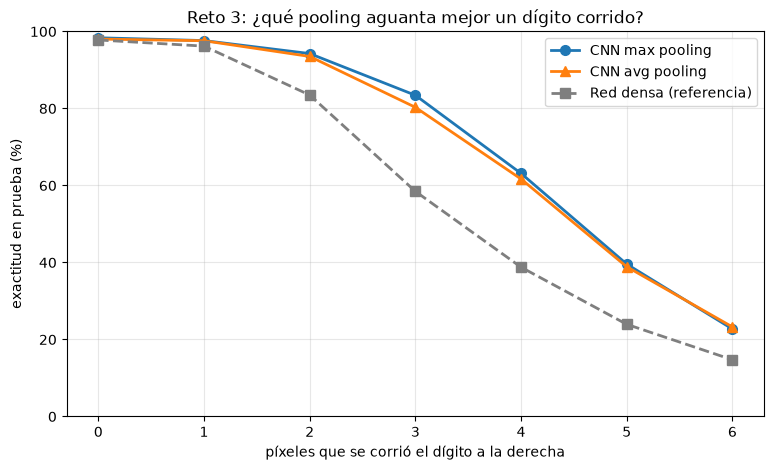

,CNN max pooling,CNN avg pooling,Red densa (referencia),max − avg (puntos)
corrimiento (px),,,,
0,98.37,98.04,97.80,0.33
1,97.64,97.60,96.20,0.04
2,94.27,93.52,83.50,0.75
3,83.44,80.31,58.48,3.13
4,63.14,61.69,38.78,1.45
5,39.58,38.89,23.94,0.69
6,22.72,23.27,14.73,-0.55


In [31]:
filas = []
for dx in CORRIMIENTOS:
    filas.append({"corrimiento (px)": dx,
                  "CNN max pooling": 100 * evaluar(resultados["CNN (LeNet-5)"]["modelo"], mover(X_test, dx), y_test)[1],
                  "CNN avg pooling": 100 * evaluar(modelo_avg, mover(X_test, dx), y_test)[1],
                  "Red densa (referencia)": 100 * evaluar(resultados["Red densa (MLP)"]["modelo"], mover(X_test, dx), y_test)[1]})
tabla_pool = pd.DataFrame(filas).set_index("corrimiento (px)")
tabla_pool["max − avg (puntos)"] = tabla_pool["CNN max pooling"] - tabla_pool["CNN avg pooling"]

plt.figure(figsize=(9, 5))
for col, marca, color in [("CNN max pooling", "o-", "tab:blue"), ("CNN avg pooling", "^-", "tab:orange"),
                          ("Red densa (referencia)", "s--", "tab:gray")]:
    plt.plot(tabla_pool.index, tabla_pool[col], marca, color=color, lw=2, ms=7, label=col)
plt.xlabel("píxeles que se corrió el dígito a la derecha"); plt.ylabel("exactitud en prueba (%)")
plt.ylim(0, 100); plt.grid(alpha=0.3); plt.legend()
plt.title("Reto 3: ¿qué pooling aguanta mejor un dígito corrido?"); plt.show()
tabla_pool.round(2)

**Respuestas del reto 3**

**Cálculo a mano (paso 1) y comprobación (paso 2):** los promedios de los 4 cuadritos son **3,75 · 1,25 · 0,75 · 5,75**, contra **6 · 2 · 2 · 9** del max pooling. `nn.AvgPool2d(2)` dio exactamente lo mismo que el cálculo a mano.

| corrimiento (px) | CNN max pooling (%) | CNN avg pooling (%) | max − avg (puntos) |
|---|---|---|---|
| 0 | 98,37 | 98,04 | +0,33 |
| 1 | 97,64 | 97,60 | +0,04 |
| 2 | 94,27 | 93,52 | +0,75 |
| 3 | 83,44 | 80,31 | **+3,13** |
| 4 | 63,14 | 61,69 | +1,45 |
| 5 | 39,58 | 38,89 | +0,69 |
| 6 | 22,72 | 23,27 | −0,55 |

**¿Cambia la exactitud sin corrimiento? ¿Es más que el ruido?**
* **Sí, un poco: el avg pooling saca 98,04 % (196 errores) contra 98,37 % (163) del max: −0,33 puntos**, más del doble del ruido (± 0,15). Es una diferencia real, aunque pequeña. En validación pasa lo mismo (97,88 % contra 98,12 %), y la red con promedio aprende más lento desde la primera época (93,34 % contra 95,52 % en validación). Las dos tienen exactamente los mismos 44 426 parámetros: el pooling no aprende nada, así que la diferencia viene solo de **cómo resume**.
* **Por qué:** en MNIST casi todo es fondo negro (cero) y los trazos son delgados. Después de la ReLU, un cuadrito de 2 × 2 donde pasa un trazo suele tener uno o dos valores altos y el resto ceros. El max guarda la señal completa ("aquí hay un borde con fuerza 9"). El promedio la mezcla con los ceros y la baja a la mitad o a la cuarta parte, como pasa en `mini` (9 → 5,75). La capa siguiente recibe señales más débiles y más borrosas, y le cuesta más separar los dígitos.

**Con corrimiento, ¿cuál aguanta mejor? ¿Por qué?**
* **El max pooling aguanta mejor en los corrimientos medianos:** +0,75 puntos con 2 px, **+3,13 con 3 px** y +1,45 con 4 px, todas por encima del ruido. Con 1 px quedan empatadas (+0,04). Con 5 y 6 px las dos se derrumban (por debajo de 40 %), y ahí la diferencia, de menos de un punto, ya no es confiable.
* **Por qué:** el max solo pregunta **si** el patrón apareció en el cuadrito. Si el trazo se corre pero su punto más fuerte sigue dentro del mismo cuadrito, el máximo es idéntico. Si se pasa al cuadrito vecino, el vecino ahora tiene un máximo igual de fuerte: la señal se mueve, pero no se debilita. El promedio, en cambio, cambia con cualquier movimiento: un trazo que queda partido entre dos cuadritos aporta la mitad a cada uno, y la capa siguiente ve una señal distinta y más débil que la que aprendió.
* **Ninguna de las dos es inmune:** las dos caen a la mitad con 4 a 5 px, porque la parte densa del final sí tiene un peso para cada posición del último mapa (4 × 4). Las dos aguantan mucho más que la red densa (58,5 % con 3 px), porque esa robustez viene sobre todo de los **filtros compartidos**, que las dos tienen.

**Qué haríamos con esto:** para dígitos (trazos delgados sobre fondo vacío) nos quedamos con el **max pooling**, que acierta más y aguanta mejor los corrimientos pequeños. Para que la red aguante corrimientos grandes, cambiar el pooling no basta: hay que entrenar con imágenes corridas (**aumento de datos**). El promedio tiene más sentido al final de redes grandes (*global average pooling*), donde resume un mapa entero.

### Reto 4 · Fashion-MNIST: lo mismo, pero con ropa

En vez de hacer una copia del cuaderno, cargamos Fashion-MNIST aquí mismo, en variables aparte (`XF_…`, `yF_…`), para no pisar los resultados de MNIST. Se hacen los mismos pasos que pide el reto: el mismo cambio en la carga (`datasets.FashionMNIST` y la carpeta `"FashionMNIST"`), la misma preparación, la misma separación de validación, el experimento 1, el experimento 3 y la matriz de confusión del experimento 5. Las funciones (`entrenar`, `evaluar`, `desordenar`, `matriz_confusion`…) son las mismas de arriba.

Entrenar: (55000, 1, 28, 28) | Validar: (5000, 1, 28, 28) | Prueba: (10000, 1, 28, 28)
Imágenes de cada prenda: [6000 6000 6000 6000 6000 6000 6000 6000 6000 6000]


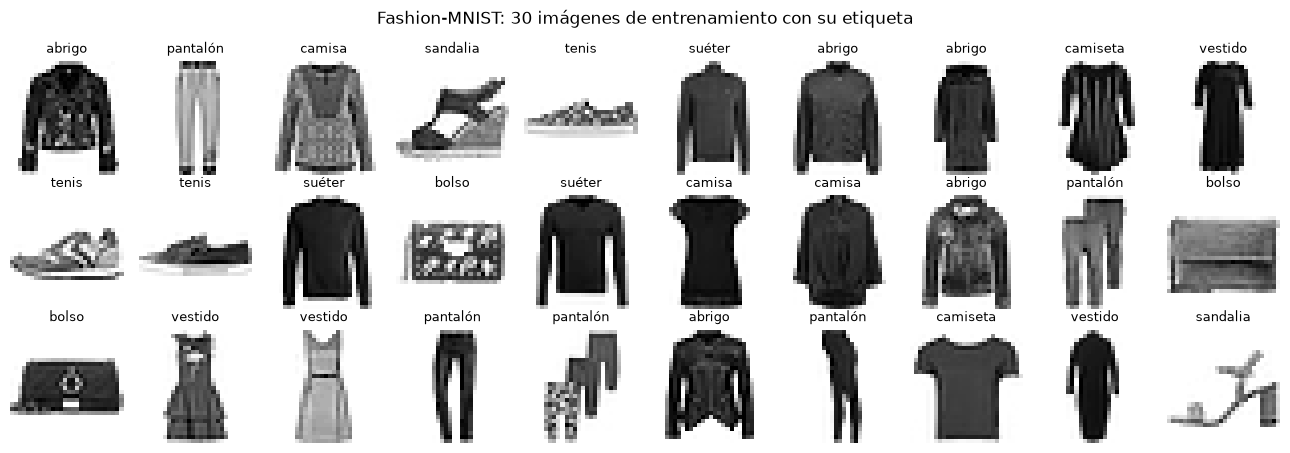

In [32]:
YA_ESTA_F = os.path.exists(os.path.join(CARPETA, "FashionMNIST", "raw", "t10k-labels-idx1-ubyte"))
if not YA_ESTA_F:
    print("Descargando Fashion-MNIST (≈ 30 MB)...")
entrenamiento_F = datasets.FashionMNIST(CARPETA, train=True, download=not YA_ESTA_F)
prueba_F = datasets.FashionMNIST(CARPETA, train=False, download=not YA_ESTA_F)

PRENDAS = ["camiseta", "pantalón", "suéter", "vestido", "abrigo", "sandalia", "camisa", "tenis", "bolso", "botín"]

XF_train_todo = (entrenamiento_F.data.float() / 255).unsqueeze(1)
yF_train_todo = entrenamiento_F.targets
XF_test, yF_test = (prueba_F.data.float() / 255).unsqueeze(1), prueba_F.targets
XF_tr, yF_tr = XF_train_todo[tr], yF_train_todo[tr]          # la misma separación 55 000 / 5 000 de arriba
XF_val, yF_val = XF_train_todo[val], yF_train_todo[val]
print("Entrenar:", tuple(XF_tr.shape), "| Validar:", tuple(XF_val.shape), "| Prueba:", tuple(XF_test.shape))
print("Imágenes de cada prenda:", np.bincount(yF_train_todo.numpy()))

fig, ejes = plt.subplots(3, 10, figsize=(13, 4.6))
for k, ax in enumerate(ejes.flat):
    ax.imshow(XF_tr[k, 0], cmap="gray_r"); ax.set_title(PRENDAS[int(yF_tr[k])], fontsize=9); ax.axis("off")
plt.suptitle("Fashion-MNIST: 30 imágenes de entrenamiento con su etiqueta")
plt.tight_layout(); plt.show()

**Experimento 1 con ropa:** las dos redes, mismas 5 épocas, mismo optimizador.

Red densa (MLP)


  época 1: pérdida 0.4248 / 0.4523   exactitud 84.85% / 83.60%   (entrenamiento / validación)


  época 2: pérdida 0.3578 / 0.3946   exactitud 86.82% / 84.92%   (entrenamiento / validación)


  época 3: pérdida 0.3235 / 0.3655   exactitud 87.95% / 86.02%   (entrenamiento / validación)


  época 4: pérdida 0.3152 / 0.3703   exactitud 88.42% / 86.38%   (entrenamiento / validación)


  época 5: pérdida 0.2717 / 0.3350   exactitud 90.12% / 87.94%   (entrenamiento / validación)
CNN (LeNet-5)


  época 1: pérdida 0.5963 / 0.6161   exactitud 76.22% / 75.50%   (entrenamiento / validación)


  época 2: pérdida 0.4718 / 0.4973   exactitud 82.35% / 80.86%   (entrenamiento / validación)


  época 3: pérdida 0.4034 / 0.4236   exactitud 85.62% / 84.90%   (entrenamiento / validación)


  época 4: pérdida 0.3617 / 0.3832   exactitud 87.04% / 85.80%   (entrenamiento / validación)


  época 5: pérdida 0.3390 / 0.3650   exactitud 87.58% / 86.82%   (entrenamiento / validación)


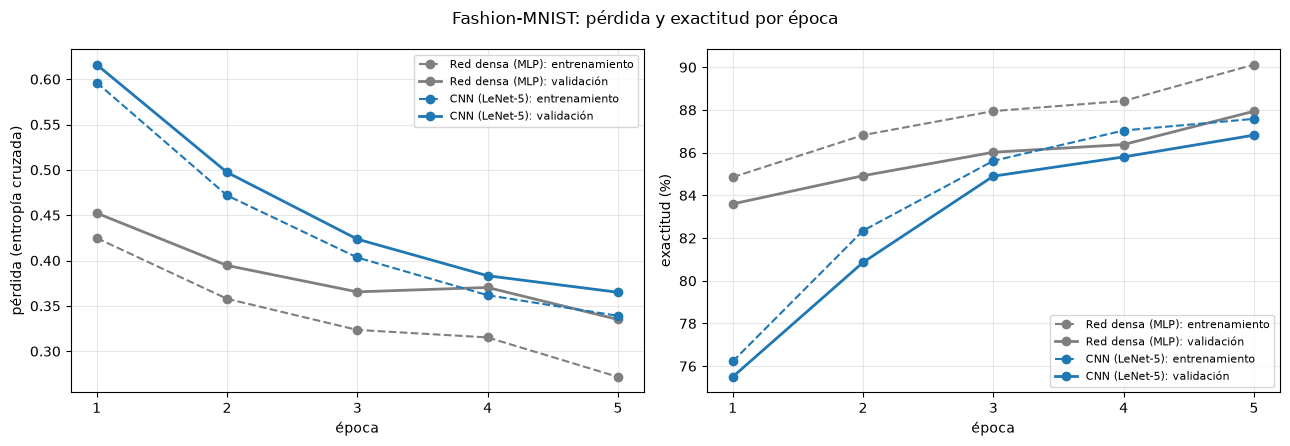

In [33]:
resultados_F = {}
for nombre, crear in COMPETIDORES.items():
    print(nombre)
    modelo, historia, segundos = entrenar(crear, XF_tr, yF_tr, XF_val, yF_val)
    _, acc = evaluar(modelo, XF_test, yF_test)
    resultados_F[nombre] = {"modelo": modelo, "historia": historia, "segundos": segundos, "acc_test": acc}

fig, ejes = plt.subplots(1, 2, figsize=(13, 4.5))
for (nombre, r), color in zip(resultados_F.items(), ["tab:gray", "tab:blue"]):
    h = r["historia"]
    ejes[0].plot(h["época"], h["pérdida entrenamiento"], "o--", color=color, label=f"{nombre}: entrenamiento")
    ejes[0].plot(h["época"], h["pérdida validación"], "o-", color=color, lw=2, label=f"{nombre}: validación")
    ejes[1].plot(h["época"], 100 * h["exactitud entrenamiento"], "o--", color=color, label=f"{nombre}: entrenamiento")
    ejes[1].plot(h["época"], 100 * h["exactitud validación"], "o-", color=color, lw=2, label=f"{nombre}: validación")
ejes[0].set_ylabel("pérdida (entropía cruzada)"); ejes[1].set_ylabel("exactitud (%)")
for ax in ejes:
    ax.set_xlabel("época"); ax.grid(alpha=0.3); ax.legend(fontsize=8); ax.set_xticks(range(1, EPOCAS + 1))
plt.suptitle("Fashion-MNIST: pérdida y exactitud por época"); plt.tight_layout(); plt.show()

**Experimento 3 con ropa:** las mismas redes, entrenadas de cero con los píxeles revueltos (la misma `PERMUTACION` de arriba).

In [34]:
acc_perm_F = {}
for nombre, crear in COMPETIDORES.items():
    modelo, _, _ = entrenar(crear, desordenar(XF_tr), yF_tr, desordenar(XF_val), yF_val, mostrar=False)
    acc_perm_F[nombre] = evaluar(modelo, desordenar(XF_test), yF_test)[1]
    print(nombre, "listo")

D, C = "Red densa (MLP)", "CNN (LeNet-5)"
tabla_reto4 = pd.DataFrame({
    "red densa": [100 * resultados[D]["acc_test"], 100 * resultados_F[D]["acc_test"]],
    "CNN": [100 * resultados[C]["acc_test"], 100 * resultados_F[C]["acc_test"]]},
    index=["MNIST (dígitos)", "Fashion-MNIST (ropa)"])
tabla_reto4["ventaja de la CNN (puntos)"] = tabla_reto4["CNN"] - tabla_reto4["red densa"]
tabla_reto4["errores densa"] = (100 * (100 - tabla_reto4["red densa"])).round().astype(int)
tabla_reto4["errores CNN"] = (100 * (100 - tabla_reto4["CNN"])).round().astype(int)
tabla_reto4["errores que se ahorra la CNN (%)"] = 100 * (1 - tabla_reto4["errores CNN"] / tabla_reto4["errores densa"])
print("Exactitud en prueba (%):"); display(tabla_reto4.round(2))

tabla_perm_F = pd.DataFrame({
    "MNIST normal": [100 * resultados[n]["acc_test"] for n in COMPETIDORES],
    "MNIST desordenado": [tabla_permutada.loc[n, "píxeles desordenados"] for n in COMPETIDORES],
    "Fashion normal": [100 * resultados_F[n]["acc_test"] for n in COMPETIDORES],
    "Fashion desordenado": [100 * acc_perm_F[n] for n in COMPETIDORES]}, index=list(COMPETIDORES))
tabla_perm_F["cambio MNIST (puntos)"] = tabla_perm_F["MNIST desordenado"] - tabla_perm_F["MNIST normal"]
tabla_perm_F["cambio Fashion (puntos)"] = tabla_perm_F["Fashion desordenado"] - tabla_perm_F["Fashion normal"]
print("Experimento 3 en los dos datasets, exactitud en prueba (%):"); display(tabla_perm_F.round(2))

Red densa (MLP) listo


CNN (LeNet-5) listo
Exactitud en prueba (%):


,red densa,CNN,ventaja de la CNN (puntos),errores densa,errores CNN,errores que se ahorra la CNN (%)
MNIST (dígitos),97.80,98.37,0.57,220,163,25.91
Fashion-MNIST (ropa),87.28,86.78,-0.50,1272,1322,-3.93


Experimento 3 en los dos datasets, exactitud en prueba (%):


,MNIST normal,MNIST desordenado,Fashion normal,Fashion desordenado,cambio MNIST (puntos),cambio Fashion (puntos)
Red densa (MLP),97.80,97.99,87.28,87.74,0.19,0.46
CNN (LeNet-5),98.37,93.56,86.78,83.31,-4.81,-3.47


**Experimento 5 con ropa:** la matriz de confusión de la CNN.

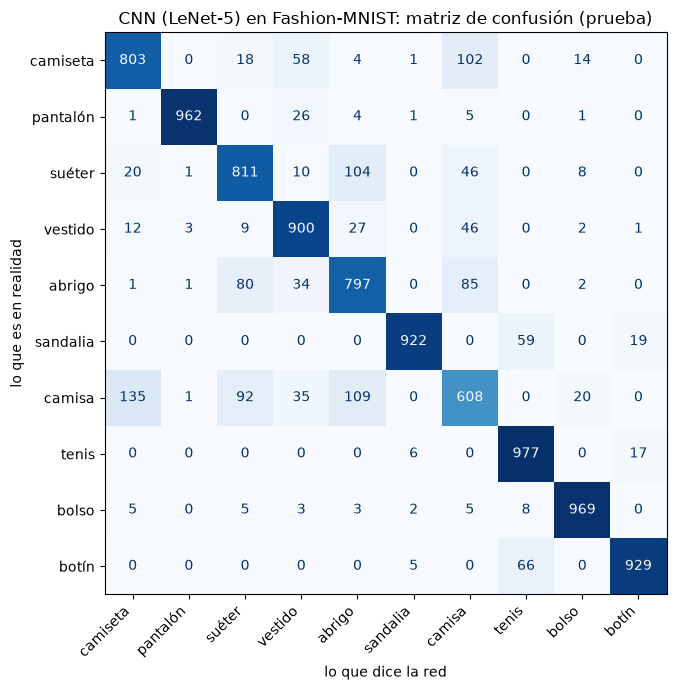

Exactitud de la CNN por prenda:


,camiseta,pantalón,suéter,vestido,abrigo,sandalia,camisa,tenis,bolso,botín
exactitud (%),80.3,96.2,81.1,90.0,79.7,92.2,60.8,97.7,96.9,92.9


Las confusiones más frecuentes:


,real,la red dice,errores
0,camisa,camiseta,135
1,camisa,abrigo,109
2,suéter,abrigo,104
3,camiseta,camisa,102
4,camisa,suéter,92
5,abrigo,camisa,85
6,abrigo,suéter,80
7,botín,tenis,66
8,sandalia,tenis,59
9,camiseta,vestido,58


In [35]:
mc_F, pred_F = matriz_confusion(resultados_F[C]["modelo"], XF_test, yF_test, nombres=PRENDAS,
                                titulo="CNN (LeNet-5) en Fashion-MNIST: matriz de confusión (prueba)")
por_prenda = pd.DataFrame({"exactitud (%)": (100 * mc_F.diagonal() / mc_F.sum(1)).round(1)}, index=PRENDAS)
print("Exactitud de la CNN por prenda:"); display(por_prenda.T)
print("Las confusiones más frecuentes:"); display(confusiones_frecuentes(mc_F, PRENDAS, n=10))

**Respuestas del reto 4**

| | red densa | CNN | ventaja de la CNN (puntos) |
|---|---|---|---|
| MNIST (dígitos) | 97,80 % (220 errores) | 98,37 % (163 errores) | **+0,57** |
| Fashion-MNIST (ropa) | 87,28 % (1 272 errores) | 86,78 % (1 322 errores) | **−0,50** |

**Ruido en Fashion-MNIST:** con una exactitud cercana a 87 %, el ruido no es ± 0,15 como en MNIST. Es de unos ± 0,34 puntos por modelo, y la diferencia entre dos modelos puede moverse ± 0,5 solo por azar.

**¿La ventaja de la CNN es mayor o menor que con dígitos? ¿Por qué?**
* **Menor: desaparece.** En MNIST la CNN gana por 0,57 puntos (26 % menos errores, unas cuatro veces el ruido). En Fashion-MNIST la densa queda 0,50 puntos arriba, del tamaño del ruido: es un **empate**, con 5 épocas.
* **Primera causa, los datos.** Lo que separa la mayoría de las prendas es la **silueta completa**: el pantalón tiene dos piernas, el vestido es largo y angosto arriba, el bolso es un rectángulo con asa, y el tenis, la sandalia y el botín son horizontales y abajo. Las imágenes vienen centradas y alineadas, así que la silueta cae siempre en los mismos píxeles. La red densa, con un peso por píxel, la aprende sin problema: es justo lo que hace bien. Los detalles locales que podrían ayudar a la CNN (botones, cuello, cremallera, textura de la tela) casi no se ven a 28 × 28 en gris.
* **Segunda causa, la capacidad y el entrenamiento.** La CNN **no está memorizando, le falta aprender**: en entrenamiento llega solo a 87,58 %, contra 90,12 % de la densa, y su pérdida de entrenamiento sigue más alta (0,339 contra 0,272). Su validación subió en todas las épocas (75,5 % → 86,8 %) y todavía no se aplanaba. LeNet-5 tiene solo 6 y 16 filtros y 44 426 parámetros, pensados para dígitos. Para ropa son pocos detectores, y 5 épocas no le alcanzan.
* **Qué probaríamos:** entrenar las dos redes 15 o 20 épocas, y darle más filtros a la CNN (32 y 64) con padding (el mejor caso del reto 2). Nuestra hipótesis es que así la CNN pasaría a la densa, pero eso hay que comprobarlo, no suponerlo.

**Experimento 3 (píxeles desordenados): ¿pasa lo mismo que con dígitos?**

| | MNIST normal → desordenado | Fashion normal → desordenado |
|---|---|---|
| Red densa | 97,80 → 97,99 (+0,19) | 87,28 → 87,74 (+0,46) |
| CNN | 98,37 → 93,56 (**−4,81**) | 86,78 → 83,31 (**−3,47**) |

* **Sí, el patrón es el mismo.** A la densa no le pasa nada: los dos cambios son del tamaño del ruido (+0,19 y +0,46), porque para ella la imagen siempre fue una lista de 784 números sin orden. La CNN cae en los dos datasets, y las caídas son 10 a 30 veces el ruido: pierde su suposición de **localidad** y sus filtros de 5 × 5 ya no encuentran bordes.
* **La caída en ropa es menor (−3,47 contra −4,81).** Concuerda con lo de arriba: en Fashion la CNN sacaba menos provecho de los vecinos (no le ganaba a la densa), así que al quitárselos pierde menos. Aun así pierde 3,5 puntos, así que sus filtros sí usaban los vecinos. El problema es que con esta arquitectura y estas épocas eso no le alcanzó para superar a una red con 7,5 veces más parámetros.

**Matriz de confusión: ¿qué prendas se confunden más? ¿Por qué esas y en qué sentido?**
* **Las prendas de la parte de arriba del cuerpo forman un bloque que se confunde entre sí:** camiseta, suéter, abrigo y camisa. La **camisa** es la peor clase por mucho, con **60,8 %** de aciertos: se la lee como camiseta (**135**), abrigo (**109**) y suéter (**92**). También van hacia otras prendas de arriba: suéter → abrigo (104), camiseta → camisa (102) y abrigo → camisa (85) o suéter (80).
* **Por qué esas:** a 28 × 28 en gris las cuatro tienen la **misma silueta**, un torso con dos mangas. Lo que las distingue es pequeño y local: el cuello y los botones de la camisa, la cremallera del abrigo, el tejido del suéter, la manga corta de la camiseta. A esta resolución esos detalles son uno o dos píxeles. La camisa es la clase "del medio": puede tener manga larga o corta, ser gruesa o delgada, así que se parece a todas y recibe errores de todas.
* **El sentido de los errores va hacia la clase más típica:** entre los zapatos, botín → tenis (**66**) y sandalia → tenis (**59**), pero tenis → botín solo 17 y tenis → sandalia solo 6. El tenis es la silueta de zapato "promedio"; las tiras y huecos de la sandalia se pierden a esta resolución, y un botín bajo parece un tenis. Algo parecido pasa con la camiseta → vestido (58): una camiseta larga parece un vestido.
* **Las que casi no se confunden** son las de silueta única: tenis (97,7 %), bolso (96,9 %) y pantalón (96,2 %).
* **Qué haríamos con esto:** si el negocio lo permite (por ejemplo, un buscador de tiendas), tratar camisa, camiseta, suéter y abrigo como "prendas de arriba" y separarlas en un segundo paso. Si no, hacen falta más resolución o más filtros para ver cuellos y botones, que es justamente donde una CNN más grande sí debería sacarle ventaja a la densa.